# Projekt zaliczeniowy – wizualizacja danych

Statystyki pochodzą z [pliku pokemon.csv w repozytorium projektu](https://github.com/Kubix-commits/Wizualizacja-Danych/blob/577ee4b05b628513ce2f63ef212b3849d01209d1/Projekt%20-%20wizualizacja/pokemon.csv).

**Zespół:** Piotr Białek, Łukasz Kubicki, Małgorzata Teślak

Jak różnią się statystyki Pokémonów i co zmienia się podczas ewolucji? Przyjrzymy się sześciu cechom: punktom życia, atakowi, obronie, atakowi specjalnemu, obronie specjalnej i szybkości. Ich suma (`Total`) pozwoli nam porównać zarówno gatunki, jak i kolejne etapy w obrębie jednej linii ewolucyjnej.

W pliku mamy 800 wpisów z generacji I–VI, w tym 386 jednotypowych i 414 dwutypowych. Odpowiadają one 721 gatunkom, ponieważ niektóre formy mają wspólny numer Pokédexu. W części opisowej zachowamy wszystkie wpisy. W testach i analizie ewolucji wybierzemy po jednej formie referencyjnej na gatunek.

**Plan analizy**

1. **Sprawdzimy dane.** Obejrzymy kolumny, zakresy wartości, braki i powtórzenia. Sprawdzimy, czy `Total` zgadza się z sumą sześciu cech i jak interpretować puste pole drugiego typu.
2. **Porównamy Pokémony jedno- i dwutypowe.** Na wykresach pudełkowych porównamy mediany i rozrzut cech. Diagnostyką rozkładów i bootstrapem uzupełnimy porównanie średnich. Pokażemy również porównanie rang. Testem t Welcha oszacujemy różnicę średniego `Total` i podamy jej przedział ufności. Wykresy rozrzutu i korelacje Pearsona pokażą, które cechy zwykle przyjmują wysokie wartości razem.
3. **Obejrzymy rozkłady statystyk.** Histogramy i współczynnik skośności pomogą ocenić, przy których cechach pojedyncze bardzo wysokie wartości wyróżniają się na tle reszty zbioru.
4. **Porównamy typy.** Sprawdzimy ich liczebność, średnie wartości cech, rozrzut obrony i udział każdej cechy w sumie punktów grupy. Przyjrzymy się też trzem typom o najwyższym średnim `Total`. Uwzględnimy oba typy: przykładowo Pokémon Fire/Flying trafi raz do grupy Fire i raz do grupy Flying.
5. **Porównamy sześć generacji.** Zestawimy średnie cech oraz średnią i medianę `Total`. Następnie wykonamy ANOVA Welcha i porównania parami Gamesa–Howella, żeby ustalić, między którymi generacjami widać różnicę średnich.
6. **Przyjrzymy się Pokémonom legendarnym.** Porównamy ich atak i obronę z pozostałymi wpisami. Dla każdego typu zestawimy liczbę i odsetek legendarnych Pokémonów, a współczynnikiem V Craméra opiszemy siłę związku między posiadaniem typu a statusem legendarnym. Istotność ocenimy testem Fishera z korektą Holma dla 18 typów.
7. **Prześledzimy zmiany w obrębie linii ewolucyjnej.** Na podstawie mapy ewolucji PokeAPI połączymy gatunki w nierozgałęzione trzyetapowe linie ewolucyjne. Sprawdzimy, które cechy rosną najbardziej. Testem t dla prób zależnych porównamy pierwszy i drugi przyrost `Total`, a analizą wariancji z powtarzanymi pomiarami porównamy wszystkie trzy etapy. Ocenimy rozkład różnic przyrostów i wyznaczymy bootstrapowy przedział ufności dla ich średniej.
8. **Zestawimy formy końcowe z gatunkami bez ewolucji.** Uwzględnimy każdą końcową gałąź i podzielimy gatunki według liczby przebytych ewolucji: zero, jedna lub dwie. Porównamy średnie cech i rozkłady `Total`, a następnie sprawdzimy, jak zmienia się obraz po wyłączeniu gatunków oznaczonych jako legendarne.

Na koniec zbierzemy najważniejsze wyniki i wskażemy, które wnioski dotyczą wszystkich wpisów, a które wybranych gatunków lub linii ewolucyjnych.

Testy i przedziały ufności traktujemy jako porównania modelowe w katalogu gatunków z generacji I–VI. Gatunki z jednej linii ewolucyjnej mogą mieć podobne cechy, co ogranicza założenie niezależności w porównaniach typów, generacji i statusu legendarnego. W analizie kolejnych etapów jednostką jest cała linia, a obserwacje w jej obrębie są powiązane. Wyniki odnosimy do zakresu danych i przyjętych form.

## 1. Wczytanie i sprawdzenie danych

In [1]:
# Sprawdzamy, czy mamy potrzebne biblioteki
import sys
from importlib.util import find_spec
from importlib.metadata import version

print("Python używany przez notebook:", sys.executable)

biblioteki = ["pandas", "numpy", "matplotlib", "seaborn", "scipy"]
brakujace = []

for biblioteka in biblioteki:
    if find_spec(biblioteka) is not None:
        print(f"{biblioteka}: {version(biblioteka)}")
    else:
        print(f"{biblioteka}: brak")
        brakujace.append(biblioteka)

if brakujace:
    print("\nUruchom w osobnej komórce notebooka:")
    print("%pip install " + " ".join(brakujace))
else:
    print("\nWszystkie potrzebne biblioteki są zainstalowane.")

# Sprawdzamy wersję SciPy potrzebną do ANOVA Welcha i testu Gamesa–Howella.
if find_spec("scipy") is not None:
    wersja_scipy = tuple(map(int, version("scipy").split(".")[:2]))
    if wersja_scipy < (1, 16):
        raise RuntimeError(
            'Potrzebujemy SciPy >= 1.16. Uruchom %pip install -U "scipy>=1.16", '
            'a następnie uruchom ponownie kernel i cały notebook.'
        )

Python używany przez notebook: /Users/lukaszkubicki/.pyenv/versions/3.11.9/bin/python
pandas: 3.0.2
numpy: 2.4.4
matplotlib: 3.10.9
seaborn: 0.13.2
scipy: 1.17.1

Wszystkie potrzebne biblioteki są zainstalowane.


In [2]:
# Wczytanie bibliotek
import pandas as pd
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.contingency import association

# Polskie nazwy do podpisów wykresów
nazwy_cech = {'HP': 'Punkty życia', 'Attack': 'Atak', 'Defense': 'Obrona',
              'Speed': 'Szybkość', 'Sp. Atk': 'Atak specjalny',
              'Sp. Def': 'Obrona specjalna', 'Total': 'Suma cech'}
nazwy_kolumn = {
    **nazwy_cech, '#': 'Numer Pokédexu', 'Name': 'Nazwa', 'Type 1': 'Pierwszy typ',
    'Type 2': 'Drugi typ', 'Generation': 'Generacja', 'Legendary': 'Status legendarny',
}
nazwy_miar = {
    'count': 'Liczba obserwacji', 'mean': 'Średnia', 'std': 'Odchylenie standardowe',
    'min': 'Minimum', '25%': 'Pierwszy kwartyl', '50%': 'Mediana',
    '75%': 'Trzeci kwartyl', 'max': 'Maksimum',
}


In [3]:
# Wczytanie danych z pliku CSV
dane = pd.read_csv('pokemon.csv')

In [4]:
# Podsumowujemy rozkłady cech liczbowych
opis_cech = dane[list(nazwy_cech)].describe().T
display(opis_cech.rename(index=nazwy_cech, columns=nazwy_miar).rename_axis("Cecha").round(2))

,Liczba obserwacji,Średnia,Odchylenie standardowe,Minimum,Pierwszy kwartyl,Mediana,Trzeci kwartyl,Maksimum
Cecha,,,,,,,,
Punkty życia,800.0,69.26,25.53,1.0,50.00,65.0,80.0,255.0
Atak,800.0,79.00,32.46,5.0,55.00,75.0,100.0,190.0
Obrona,800.0,73.84,31.18,5.0,50.00,70.0,90.0,230.0
Szybkość,800.0,68.28,29.06,5.0,45.00,65.0,90.0,180.0
Atak specjalny,800.0,72.82,32.72,10.0,49.75,65.0,95.0,194.0
Obrona specjalna,800.0,71.90,27.83,20.0,50.00,70.0,90.0,230.0
Suma cech,800.0,435.10,119.96,180.0,330.00,450.0,515.0,780.0


In [5]:
# Sprawdzamy rozmiar danych i typy kolumn
opis_kolumn = pd.DataFrame({
    'Rodzaj danych': dane.dtypes.map(
        lambda typ: 'logiczne' if pd.api.types.is_bool_dtype(typ)
        else 'liczbowe' if pd.api.types.is_numeric_dtype(typ) else 'tekstowe'
    ),
    'Liczba wartości': dane.count(),
    'Różne wartości': dane.nunique(),
})
display(opis_kolumn.rename(index=nazwy_kolumn).rename_axis('Kolumna'))
print('Liczba wpisów:', len(dane))
print('Liczba różnych numerów Pokémonów:', dane['#'].nunique())
print('Wpisy jednotypowe:', dane['Type 2'].isna().sum())
print('Wpisy dwutypowe:', dane['Type 2'].notna().sum())

,Rodzaj danych,Liczba wartości,Różne wartości
Kolumna,,,
Numer Pokédexu,liczbowe,800,721
Nazwa,tekstowe,800,800
Pierwszy typ,tekstowe,800,18
Drugi typ,tekstowe,414,18
Suma cech,liczbowe,800,200
Punkty życia,liczbowe,800,94
Atak,liczbowe,800,111
Obrona,liczbowe,800,103
Atak specjalny,liczbowe,800,105


Liczba wpisów: 800
Liczba różnych numerów Pokémonów: 721
Wpisy jednotypowe: 386
Wpisy dwutypowe: 414


In [6]:
# Oglądamy pierwsze 5 wpisów
podglad = dane.head().rename(columns=nazwy_kolumn).copy()
podglad['Status legendarny'] = podglad['Status legendarny'].map({False: 'Zwykły', True: 'Legendarny'})
display(podglad.fillna('—'))

,Numer Pokédexu,Nazwa,Pierwszy typ,Drugi typ,Suma cech,Punkty życia,Atak,Obrona,Atak specjalny,Obrona specjalna,Szybkość,Generacja,Status legendarny
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,Zwykły
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,Zwykły
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,Zwykły
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,Zwykły
4,4,Charmander,Fire,—,309,39,52,43,60,50,65,1,Zwykły


In [7]:
# Liczymy puste pola w każdej kolumnie
display(dane.isna().sum().rename(index=nazwy_kolumn).rename_axis('Kolumna')
        .to_frame('Liczba braków'))

,Liczba braków
Kolumna,
Numer Pokédexu,0
Nazwa,0
Pierwszy typ,0
Drugi typ,386
Suma cech,0
Punkty życia,0
Atak,0
Obrona,0
Atak specjalny,0


W pliku mamy 800 wpisów i 721 różnych numerów Pokémonów. Powtórzony numer nie musi oznaczać błędu: np. zwykła forma i forma Mega mają ten sam numer, ale inne statystyki. Zostawiamy je jako osobne wpisy.

386 wpisów (48,25%) ma tylko jeden typ, a 414 (51,75%) ma dwa typy. Puste pole w `Type 2` oznacza brak drugiego typu. Nie jest to brakująca informacja o statystykach Pokémona, więc nie usuwamy wpisu i nie dopisujemy mu drugiego typu.

Sprawdzimy też duplikaty, zakresy cech i zgodność `Total` z sumą sześciu cech.

In [8]:
# Sprawdzamy, czy dane wymagają poprawienia
cechy = ['HP', 'Attack', 'Defense', 'Sp. Atk', 'Sp. Def', 'Speed']
print('Powtórzone wiersze:', dane.duplicated().sum())
print('Powtórzone nazwy:', dane['Name'].duplicated().sum())
print('Ujemne wartości cech:', (dane[cechy] < 0).sum().sum())
print('Niezgodna suma Total:', (dane['Total'] != dane[cechy].sum(axis=1)).sum())
print('Braki poza Type 2:', dane.drop(columns='Type 2').isna().sum().sum())
print('Zakresy wartości cech:')
display(dane[cechy].agg(['min', 'max']).rename(index=nazwy_miar, columns=nazwy_cech))
print('Puste lub dodatkowe spacje w nazwach i typach:')
for kolumna in ['Name', 'Type 1', 'Type 2']:
    tekst = dane[kolumna].dropna()
    print(nazwy_kolumn[kolumna], ((tekst != tekst.str.strip()) | (tekst.str.strip() == '')).sum())
print('Generacje:', sorted(dane['Generation'].unique()))
print('Status legendarny:', sorted(dane['Legendary'].unique()))

Powtórzone wiersze: 0
Powtórzone nazwy: 0
Ujemne wartości cech: 0
Niezgodna suma Total: 0
Braki poza Type 2: 0
Zakresy wartości cech:


,Punkty życia,Atak,Obrona,Atak specjalny,Obrona specjalna,Szybkość
Minimum,1,5,5,10,20,5
Maksimum,255,190,230,194,230,180


Puste lub dodatkowe spacje w nazwach i typach:
Nazwa 0
Pierwszy typ 0
Drugi typ 0
Generacje: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Status legendarny: [np.False_, np.True_]


Nie znaleźliśmy powtórzonych całych wierszy ani nazw, ujemnych wartości cech, błędnych sum `Total` ani dodatkowych spacji. Generacje mają wartości od 1 do 6, a status legendarny to `False` lub `True`.

Poza `Type 2` nie ma pustych pól. Puste pola w tej kolumnie zostawiamy, ponieważ dotyczą Pokémonów jednotypowych. Przeprowadzone sprawdzenia nie wskazują potrzeby usuwania wpisów ani uzupełniania statystyk. Dużych wartości też nie usuwamy automatycznie — sam wysoki wynik nie dowodzi błędu.

## 2. Pokémony jednotypowe i dwutypowe oraz zależności między cechami

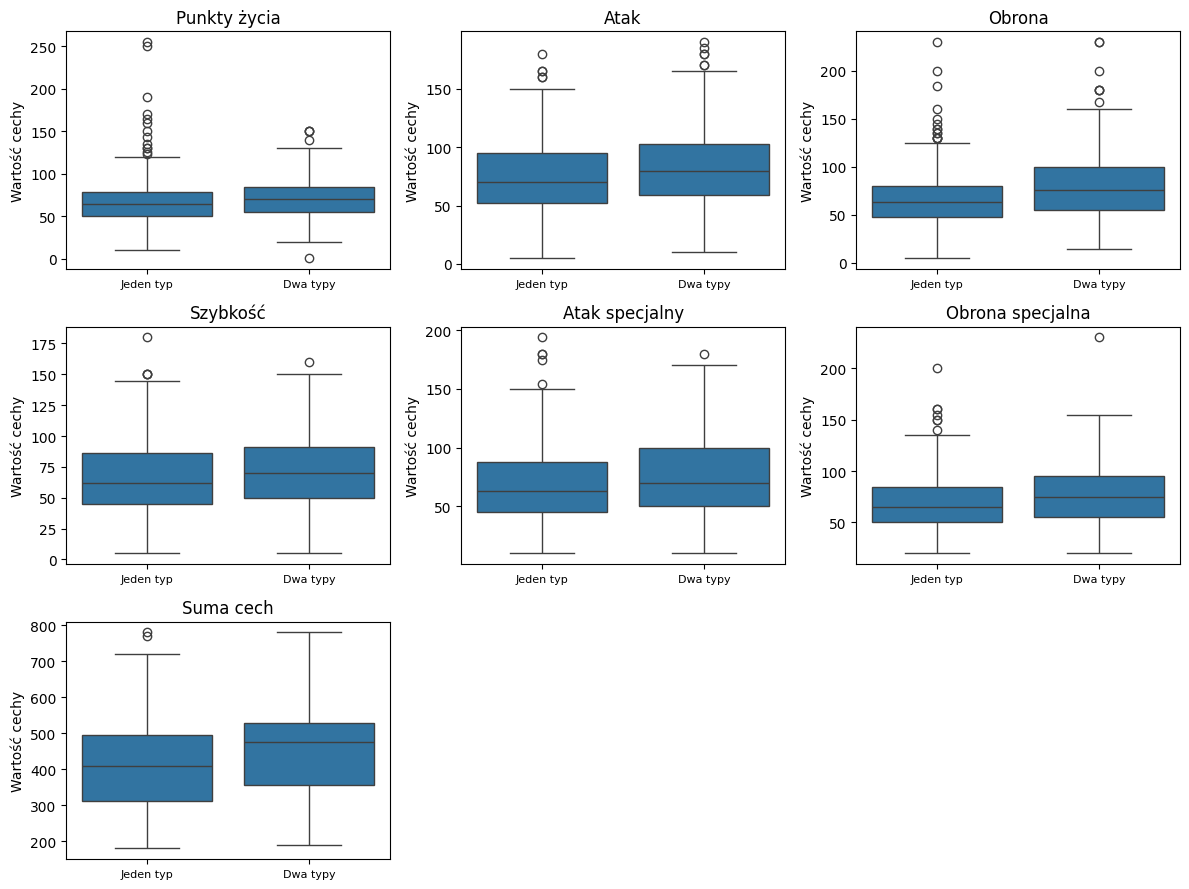

In [9]:
# Porównujemy wpisy z drugim typem i bez niego
dane['ma_drugi_typ'] = dane['Type 2'].notna()
porownywane_cechy = ['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def', 'Total']
plt.figure(figsize=(12, 9))
for i, cecha in enumerate(porownywane_cechy):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(data=dane, x='ma_drugi_typ', y=cecha, order=[False, True])
    plt.title(nazwy_cech[cecha])
    plt.xlabel('')
    plt.xticks([0, 1], ['Jeden typ', 'Dwa typy'], fontsize=8)
    plt.ylabel('Wartość cechy')
plt.tight_layout()
plt.show()

Porównujemy dwie osobne grupy: 386 wpisów Pokémonów jednotypowych i 414 wpisów Pokémonów dwutypowych. Każdy wpis należy tylko do jednej z tych grup.

W grupie dwutypowej mediany wszystkich porównywanych cech są wyższe. Mediana `Total` wynosi 475, a w grupie jednotypowej 410. Rozkłady jednak częściowo się pokrywają. Nie oznacza to, że każdy Pokémon dwutypowy ma wyższe statystyki ani że posiadanie drugiego typu powoduje ich wzrost.

### Porównanie średniej sumy cech — test Welcha

Pytamy, czy średnia suma cech różni się między gatunkami jedno- i dwutypowymi. Wybieramy jedną formę referencyjną na numer Pokédexu. Słownik poniżej określa wybór przy alternatywnych formach. Wykres powyżej obejmuje 800 wpisów, a test i diagnostyka poniżej obejmują 721 gatunków.

Stawiamy hipoteze zerowa, ze srednie sum cech dla pokemonow jedno i dwutypowych sa takie same, przeciw hipotezie alternatywnej ze te srednie istotnie sie roznia. Do zweryfikowania tej hipotezy uzyjemy test Welcha ktory uwzględnia liczebności grup oraz ich wariancje i dopuszcza nierówne wariancje.


Przy gatunkach z dodatkowymi formami wybieramy nazwę bazową, a pozostałe decyzje zapisujemy w słowniku. Przyjmujemy m.in. Deoxys Normal Forme, Aegislash Shield Forme oraz Average Size dla Pumpkaboo i Gourgeist. Jest to jawna konwencja analizy. Inny wybór może zmienić wartości cech, a w części przypadków także typ lub sumę cech. Wszystkie etapy zwykłych ewolucji pozostają osobnymi gatunkami. Wybór jednej formy na gatunek daje 721 obserwacji.

In [2]:
# Wybieramy jedną postać na numer Pokédexu.
# Słownik wskazuje wybór dla 15 gatunków z nazwami wymagającymi decyzji.
# Pozostałe gatunki obsługujemy regułą nazwy bazowej poniżej.
formy_referencyjne = {
    386: "DeoxysNormal Forme", 413: "WormadamPlant Cloak",
    487: "GiratinaAltered Forme", 492: "ShayminLand Forme",
    555: "DarmanitanStandard Mode", 641: "TornadusIncarnate Forme",
    642: "ThundurusIncarnate Forme", 645: "LandorusIncarnate Forme",
    647: "KeldeoOrdinary Forme", 648: "MeloettaAria Forme",
    678: "MeowsticMale", 681: "AegislashShield Forme",
    710: "PumpkabooAverage Size", 711: "GourgeistAverage Size",
    720: "HoopaHoopa Confined",
}
indeksy_form = []
for numer, grupa in dane.groupby("#"):
    nazwy = grupa["Name"].tolist()
    if numer in formy_referencyjne:
        nazwa = formy_referencyjne[numer]
    else:
        # Nazwa gatunku bez dopisku jest też prefiksem nazw jego form.
        nazwa = min(nazwy, key=len)
        if not all(wariant.startswith(nazwa) for wariant in nazwy):
            raise ValueError(f"Brak reguły wyboru formy dla numeru {numer}")
    indeksy_form.append(grupa.loc[grupa["Name"].eq(nazwa)].index.item())

dane_bazowe = dane.loc[indeksy_form].copy()
dane_bazowe["ma_drugi_typ"] = dane_bazowe["Type 2"].notna()
grupy_typow = dane_bazowe.groupby("ma_drugi_typ")["Total"]
print(grupy_typow.agg(["size", "mean", "median", "std", "skew"]).rename(columns={**nazwy_miar, "size": "Liczba gatunków", "median": "Mediana", "skew": "Skośność"}).round(2)
      .rename(index={False: "Jeden typ", True: "Dwa typy"}).rename_axis("Liczba typów").to_string())
dwa_typy = grupy_typow.get_group(True)
jeden_typ = grupy_typow.get_group(False)
test_welcha = stats.ttest_ind(dwa_typy, jeden_typ, equal_var=False)
przedzial_roznicy = test_welcha.confidence_interval()
print(f"Różnica średnich (dwa typy − jeden typ): {dwa_typy.mean() - jeden_typ.mean():.2f} pkt")
print(f"t = {test_welcha.statistic:.3f}, df = {test_welcha.df:.2f}, p = {test_welcha.pvalue:.6g}")
print(f"95% PU: [{przedzial_roznicy.low:.2f}, {przedzial_roznicy.high:.2f}] pkt")


NameError: name 'dane' is not defined

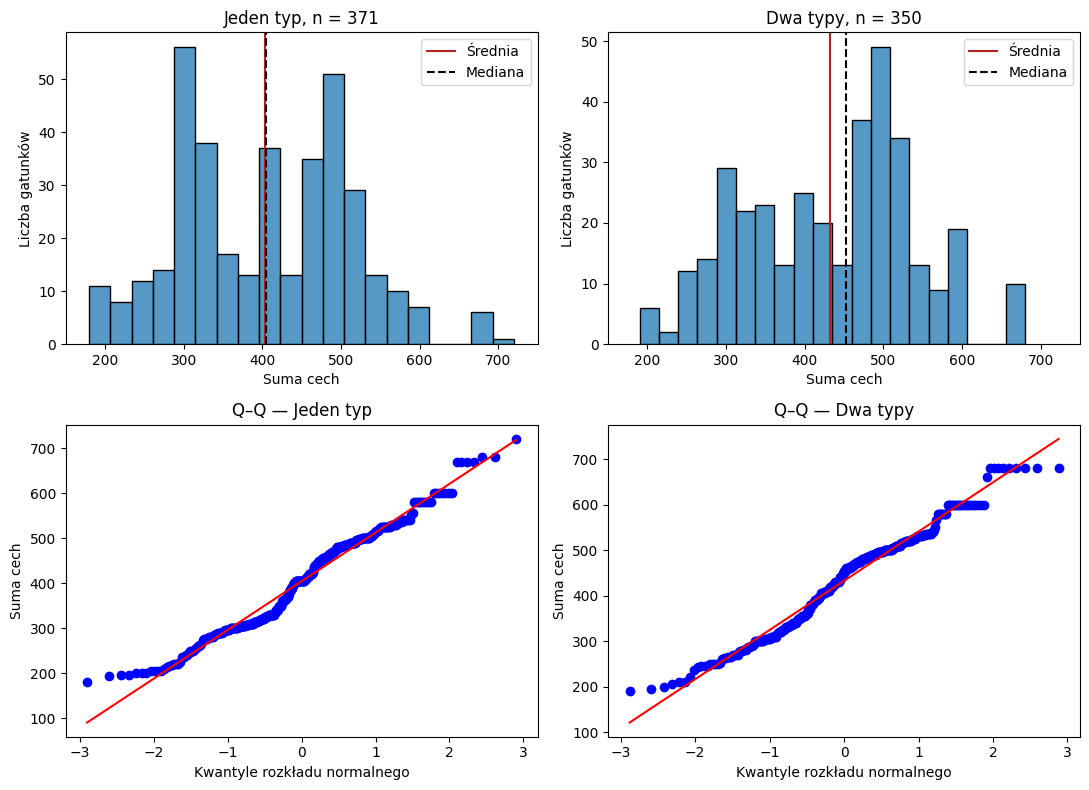

95% bootstrapowy PU różnicy średnich = [12.63, 44.33] pkt
Test U Manna–Whitneya, U = 74680.5, p = 0.000482136


In [ ]:
# Oglądamy dokładnie te grupy, które porównujemy testem Welcha.
fig, osie = plt.subplots(2, 2, figsize=(11, 8))
for kolumna, (nazwa, proba) in enumerate([("Jeden typ", jeden_typ), ("Dwa typy", dwa_typy)]):
    sns.histplot(proba, bins=20, ax=osie[0, kolumna])
    osie[0, kolumna].axvline(proba.mean(), color="firebrick", label="Średnia")
    osie[0, kolumna].axvline(proba.median(), color="black", linestyle="--", label="Mediana")
    osie[0, kolumna].set(title=f"{nazwa}, n = {len(proba)}",
                        xlabel="Suma cech", ylabel="Liczba gatunków", xlim=(150, 750))
    osie[0, kolumna].legend()
    stats.probplot(proba, dist="norm", plot=osie[1, kolumna])
    osie[1, kolumna].set(title=f"Q–Q — {nazwa}",
                        xlabel="Kwantyle rozkładu normalnego", ylabel="Suma cech")
plt.tight_layout()
plt.show()

# Oceniamy niepewność różnicy średnich, losując osobno wewnątrz każdej grupy.
def roznica_srednich_typow(dwa_typy, jeden_typ, axis=-1):
    return np.mean(dwa_typy, axis=axis) - np.mean(jeden_typ, axis=axis)

bootstrap_typow = stats.bootstrap(
    (dwa_typy.to_numpy(), jeden_typ.to_numpy()), roznica_srednich_typow,
    confidence_level=0.95, n_resamples=10000, batch=500, method="BCa",
    rng=np.random.default_rng(20261122),
)
print(f"95% bootstrapowy PU różnicy średnich = "
      f"[{bootstrap_typow.confidence_interval.low:.2f}, "
      f"{bootstrap_typow.confidence_interval.high:.2f}] pkt")

# Dodatkowe porównanie rang uwzględnia powtarzające się wartości Total.
test_rangowy_typow = stats.mannwhitneyu(
    dwa_typy, jeden_typ, alternative="two-sided", method="asymptotic"
)
print(f"Test U Manna–Whitneya, U = {test_rangowy_typow.statistic:.1f}, "
      f"p = {test_rangowy_typow.pvalue:.6g}")


Średnia sumy cech wynosi 404,12 pkt dla 371 gatunków jednotypowych i 432,61 pkt dla 350 dwutypowych. Mediany wynoszą odpowiednio 405 i 452,5 pkt. Odchylenia standardowe są zbliżone i wynoszą 108,91 oraz 108,71 pkt. Skośność wynosi około 0,149 i −0,026. Wykresy pokazują również nieregularny kształt rozkładów, dlatego ocenę opieramy na kilku miarach i diagnostyce.

Różnica średnich wynosi **28,49 pkt**. Test Welcha daje p = 0,000469 i 95% przedział ufności 12,57–44,41 pkt. Bootstrapowy przedział 12,63–44,33 pkt daje podobną ocenę niepewności tej różnicy. Przy liczebnościach obu grup i niewielkiej skośności zachowujemy Welcha jako główną analizę średniej.

Uzupełniający test U Manna–Whitneya daje p około 0,000482. Porównuje rozkłady poprzez rangi. Interpretacja jako test różnicy median wymaga dodatkowych założeń dotyczących kształtu rozkładów. Mediany prezentujemy jako dodatkową charakterystykę grup. Bootstrap, Welch i porównanie rang korzystają z założenia niezależności obserwacji.




Sprawdzimy teraz zależności między cechami dla wszystkich 800 wpisów. Kolor pokazuje, czy Pokémon jest jednotypowy, czy dwutypowy. Każdy wpis jest liczony tylko raz.

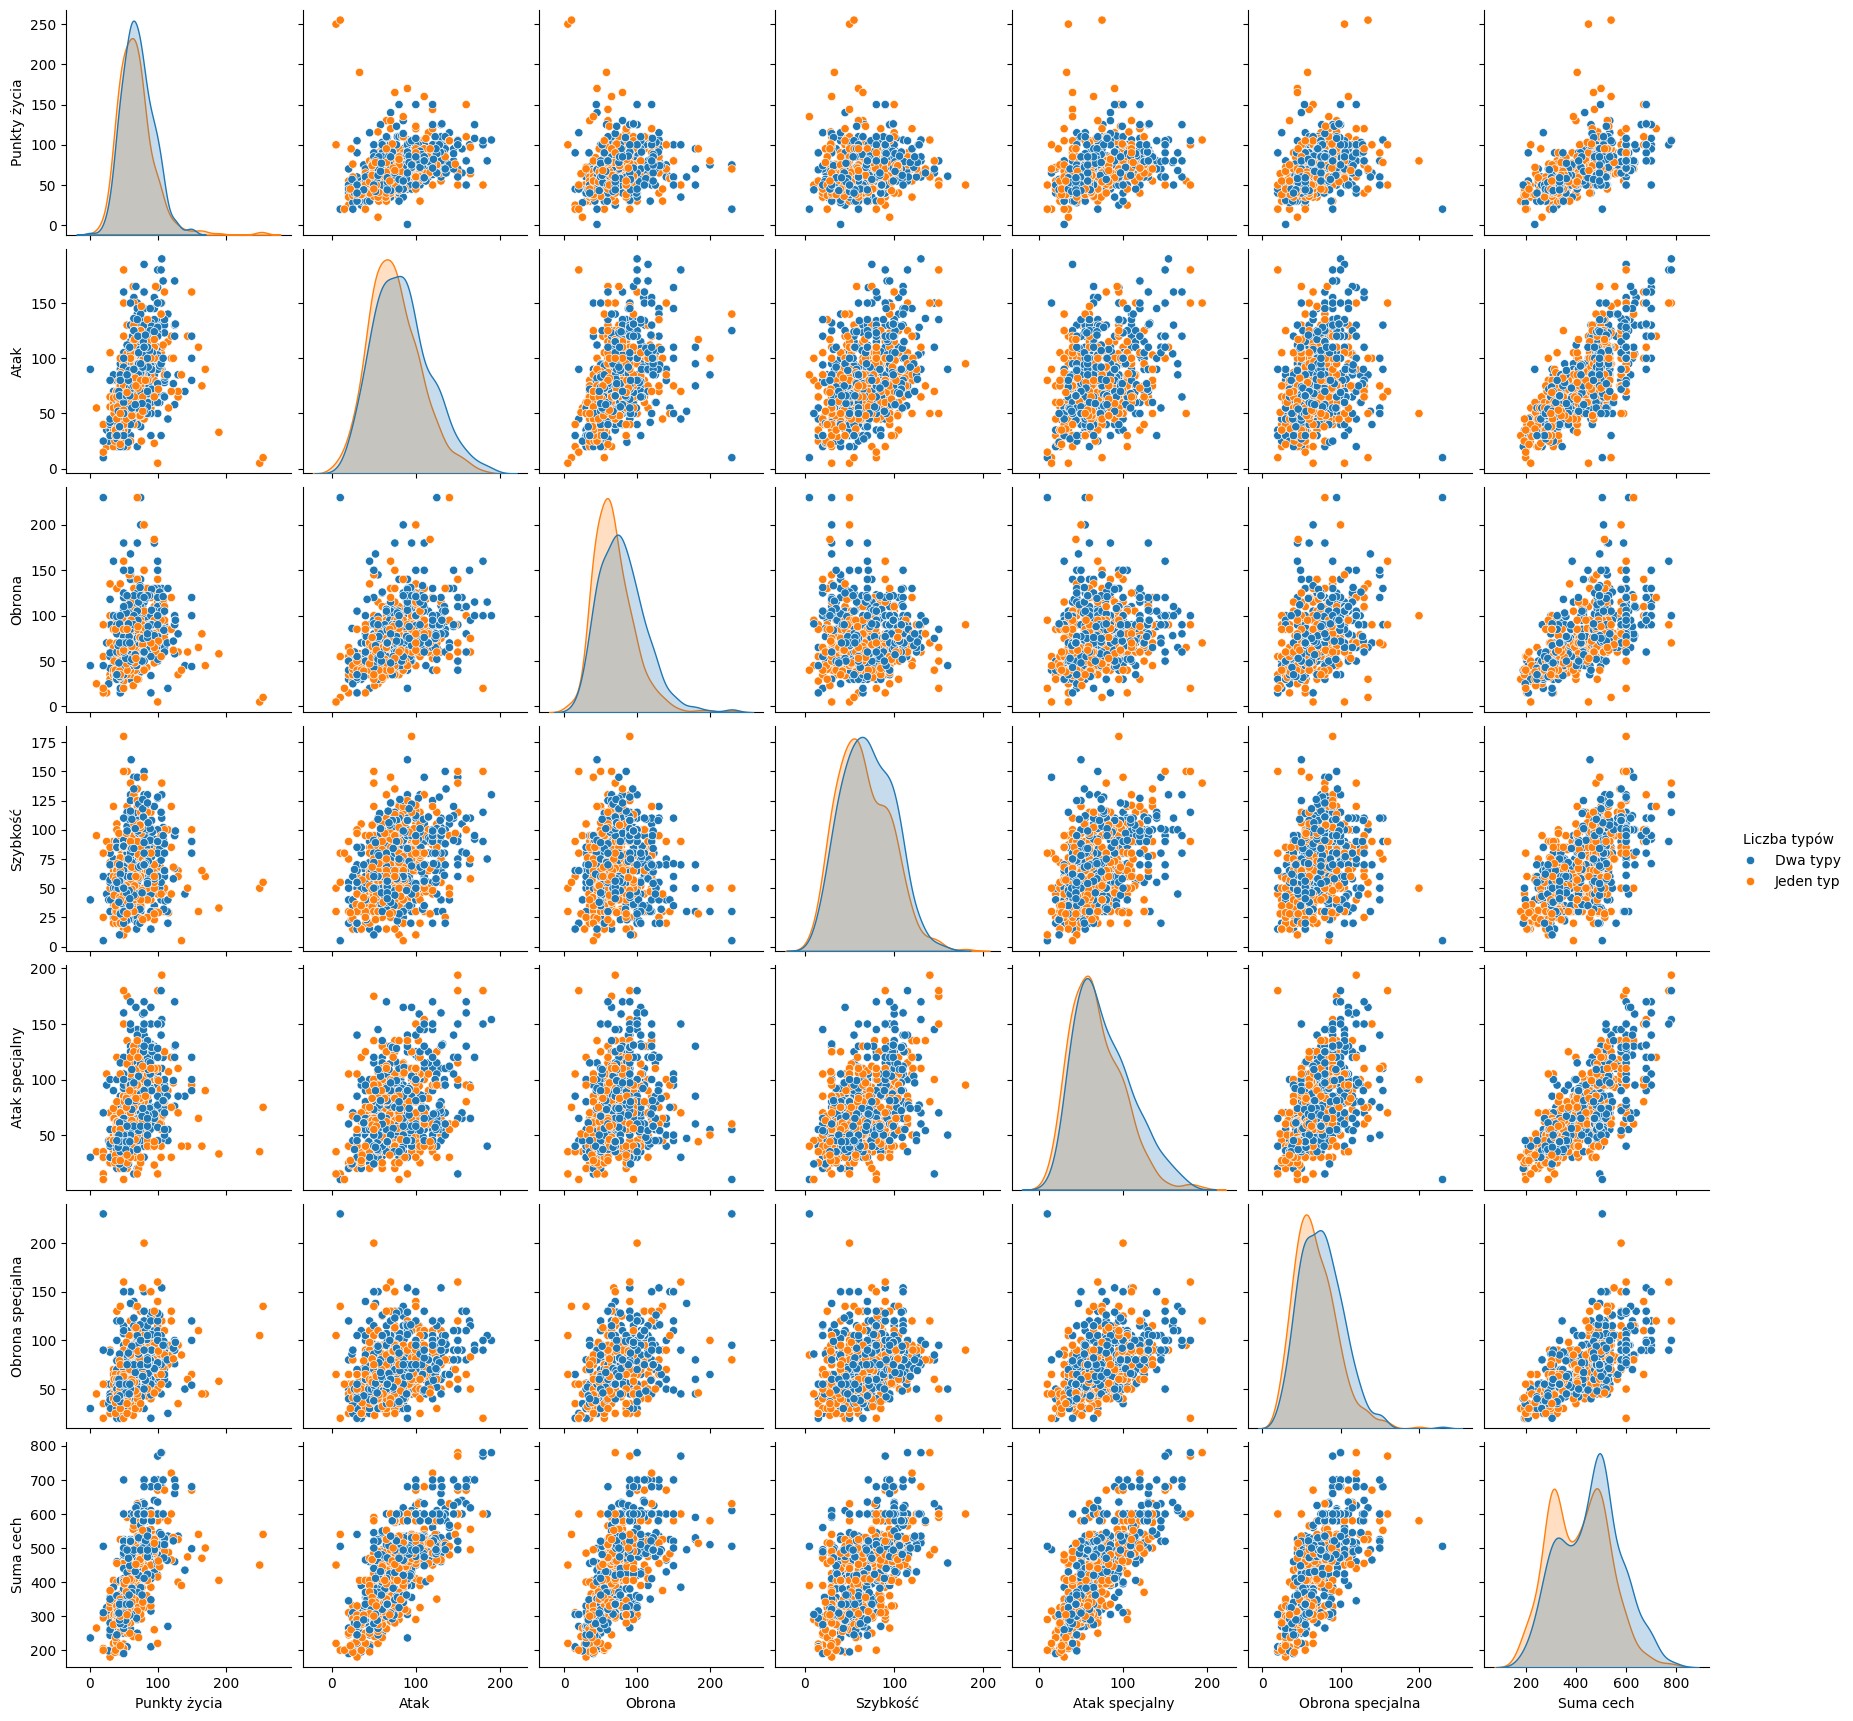

In [ ]:
# Kolory opisujemy słowami zamiast True i False
dane_do_wykresu = dane.assign(Liczba_typow=dane['ma_drugi_typ'].map({False: 'Jeden typ', True: 'Dwa typy'}))
sns.pairplot(dane_do_wykresu.rename(columns={**nazwy_cech, 'Liczba_typow': 'Liczba typów'}),
             vars=[nazwy_cech[cecha] for cecha in porownywane_cechy], hue='Liczba typów')
plt.show()

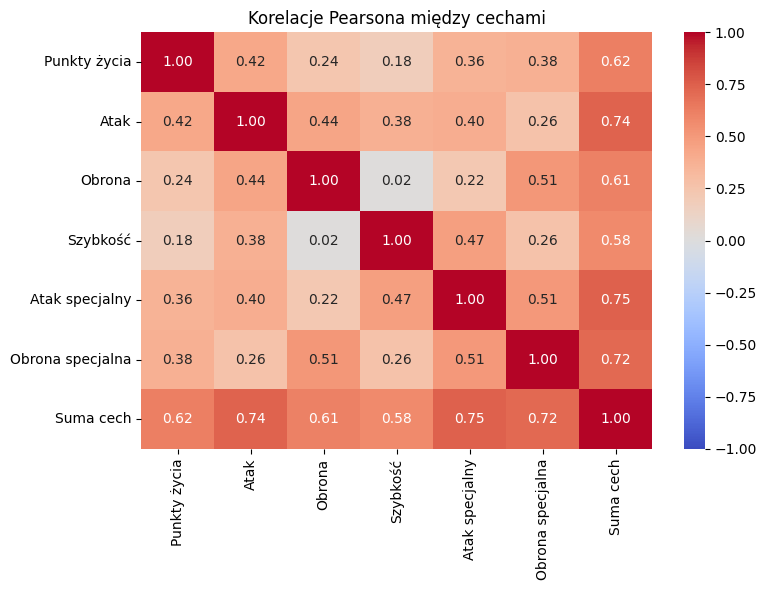

In [ ]:
# Sprawdzamy korelacje między cechami
plt.figure(figsize=(8, 6))
sns.heatmap(dane[porownywane_cechy].rename(columns=nazwy_cech).corr(method='pearson'), annot=True,
            cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt='.2f')
plt.title('Korelacje Pearsona między cechami')
plt.tight_layout()
plt.show()

Najwyższe korelacje między sześcioma pojedynczymi cechami wynoszą około 0,51: dla ataku specjalnego i obrony specjalnej oraz obrony i obrony specjalnej. Nie wszystkie pary są wyraźnie powiązane — np. korelacja obrony z szybkością wynosi około 0,02.

`Total` jest sumą tych sześciu cech. Jego korelacja z nimi wynika więc częściowo z samego sposobu obliczania sumy. Korelacja opisuje współwystępowanie wartości, a nie dowodzi, że jedna cecha powoduje zmianę drugiej.

Tu dodamy korelacje pomiedzy pokemonami jednotypowymi a dwutypowymi

## 3. Rozkłady statystyk

Sprawdzimy rozkłady punktów życia, ataku, obrony, szybkości, ataku specjalnego, obrony specjalnej i ich sumy (`Total`). Każdy z 800 wpisów liczymy raz, niezależnie od liczby typów.

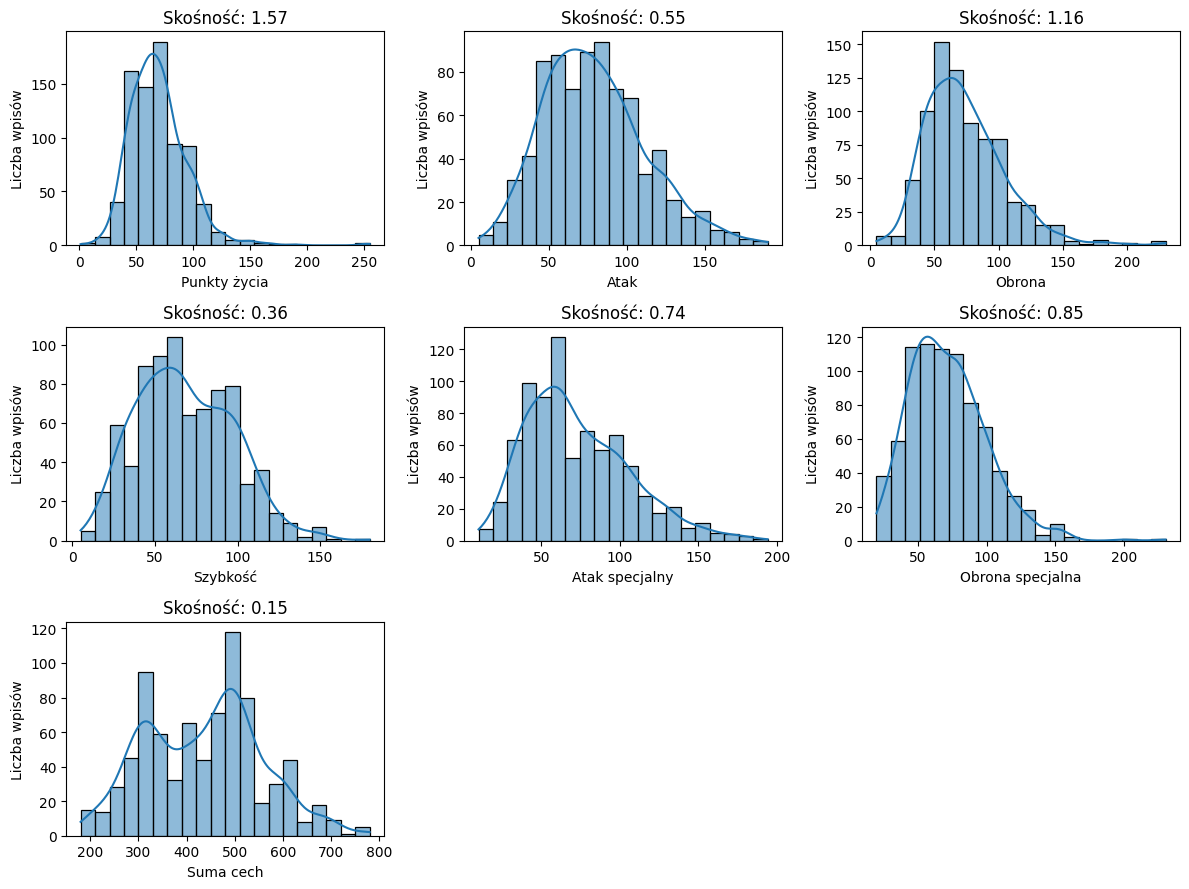

In [14]:
# Oglądamy rozkłady i liczymy skośność
plt.figure(figsize=(12, 9))
for i, cecha in enumerate(porownywane_cechy):
    plt.subplot(3, 3, i + 1)
    sns.histplot(data=dane, x=cecha, bins=20, kde=True)
    plt.title(f'Skośność: {dane[cecha].skew():.2f}')
    plt.xlabel(nazwy_cech[cecha])
    plt.ylabel('Liczba wpisów')
plt.tight_layout()
plt.show()

Skośność sześciu cech oraz `Total` jest dodatnia, ale ma różną siłę. Największa jest dla punktów życia (około 1,57) i obrony (około 1,16). Dla `Total` jest niewielka (około 0,15). Nie wszystkie rozkłady są więc mocno skośne. Sama skośność nie przesądza też o potrzebie zmiany skali danych.

## 4. Porównanie typów

W tej części grupujemy Pokémony według ich typów, uwzględniając `Type 1` i `Type 2`. Pokémon Fire/Flying należy do grupy Fire i do grupy Flying, ale w każdej z nich jest liczony tylko raz.

Nadal analizujemy 800 wpisów: 386 jednotypowych i 414 dwutypowych. Osobny zbiór do porównań typów służy tylko do przypisania każdego wpisu do właściwych grup. Nie oznacza, że pojawiły się dodatkowe Pokémony.

Grupy typów częściowo obejmują te same wpisy, dlatego ich liczebności nie sumujemy jako liczby Pokémonów.

In [15]:
# Tworzymy osobny zbiór do porównań typów
# Numer wpisu pozwala rozróżnić formy tego samego Pokémona
dane_typy = dane.copy()
dane_typy['Wpis'] = dane_typy.index
dane_typy = dane_typy.melt(
    id_vars=['Wpis', 'Name', 'Legendary', 'Total', 'HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def'],
    value_vars=['Type 1', 'Type 2'], value_name='Typ'
).dropna(subset=['Typ'])
# Wpis może pojawić się tylko raz w obrębie danego typu
dane_typy = dane_typy.drop_duplicates(subset=['Wpis', 'Typ'])
print('Liczba wpisów w pliku:', len(dane))
print('Liczba przypisań do typów:', len(dane_typy))
kolumny_statystyk = ['Total', 'HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def']
zsumowane_dane = dane_typy.groupby('Typ')[kolumny_statystyk].sum().reset_index()

Liczba wpisów w pliku: 800
Liczba przypisań do typów: 1214


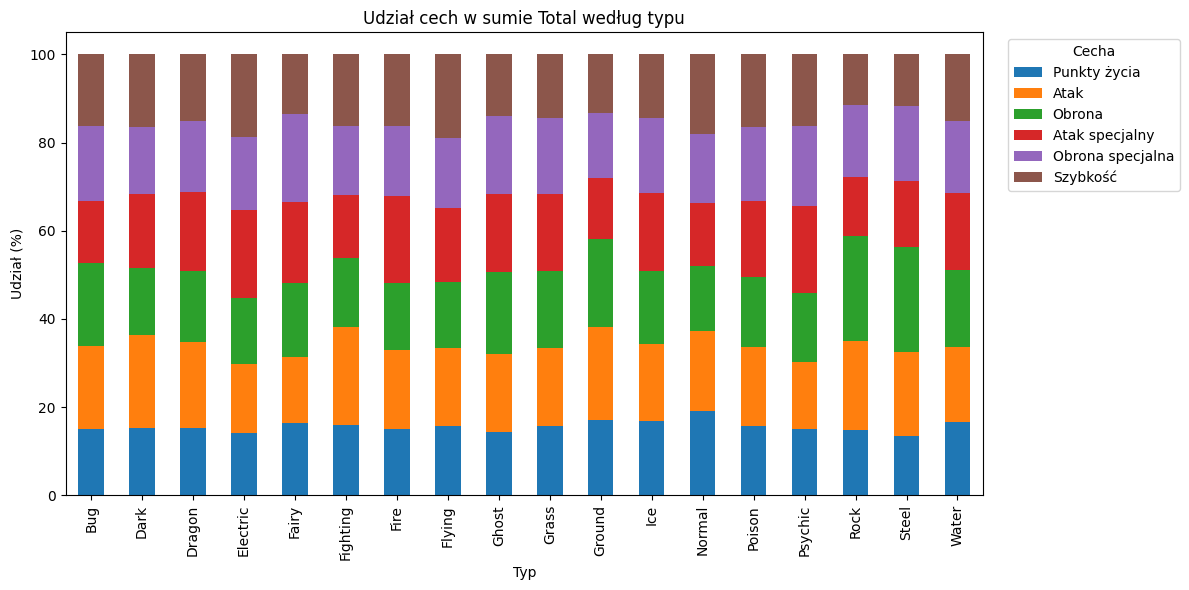

In [16]:
# Pokazujemy, z czego składa się suma cech w każdej grupie
sumy_typow = zsumowane_dane.set_index('Typ')
udzialy = (
    sumy_typow[cechy]
    .div(sumy_typow['Total'], axis='index')
    .mul(100)
    .rename(columns=nazwy_cech)
)
udzialy.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Udział cech w sumie Total według typu')
plt.xlabel('Typ')
plt.ylabel('Udział (%)')
plt.legend(title='Cecha', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Dla grupy Steel największy udział w sumie cech ma obrona, a najmniejszy szybkość. Dla Fighting i Ground największy udział ma atak. W każdym słupku udziały sumują się do 100%.

Liczymy udział cechy w sumie `Total` całej grupy. To inne obliczenie niż średnia procentowych udziałów dla pojedynczych Pokémonów. Duży udział nie oznacza też najwyższej wartości cechy wśród wszystkich typów. Porównamy teraz średnie.

In [17]:
# Pokazujemy średnie i liczebność grup uwzględniających oba typy
srednie_dane = dane_typy.groupby('Typ')[kolumny_statystyk].mean().reset_index()
tabela_srednich = srednie_dane.copy()
tabela_srednich['Liczba wpisów'] = tabela_srednich['Typ'].map(dane_typy['Typ'].value_counts())
display(tabela_srednich.set_index('Typ').rename(columns=nazwy_cech)
        .rename_axis('Średnie cech i liczebność', axis='columns').round(2))

Średnie cech i liczebność,Suma cech,Punkty życia,Atak,Obrona,Szybkość,Atak specjalny,Obrona specjalna,Liczba wpisów
Typ,,,,,,,,
Bug,379.53,56.74,71.76,71.11,61.68,53.57,64.67,72
Dark,460.90,70.24,96.78,70.94,75.84,77.45,69.65,51
Dragon,541.76,82.90,105.76,86.62,82.14,97.44,86.90,50
Electric,444.84,63.20,69.52,66.54,82.94,88.96,73.68,50
Fairy,415.92,68.47,61.58,70.40,55.85,76.50,83.12,40
Fighting,470.11,74.57,104.66,74.06,76.53,66.92,73.38,53
Fire,467.11,70.16,84.11,70.09,75.42,93.00,74.33,64
Flying,453.83,71.37,80.23,68.23,86.39,76.37,71.26,101
Ghost,436.87,62.83,76.93,81.52,61.15,77.48,76.96,46


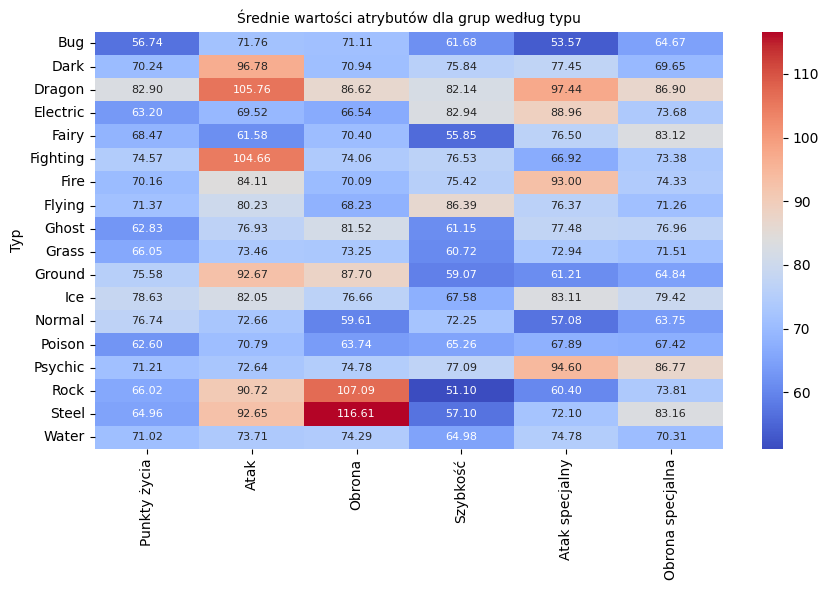

In [18]:
plt.figure(figsize=(9, 6))
sns.heatmap(srednie_dane[[ 'HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def']].rename(columns=nazwy_cech),
             yticklabels=srednie_dane['Typ'], xticklabels=True, cmap='coolwarm',
               fmt=".2f", annot=True, annot_kws={"size": 8})
plt.title("Średnie wartości atrybutów dla grup według typu", fontsize=10)
plt.ylabel('Typ')
plt.tight_layout()
plt.show()

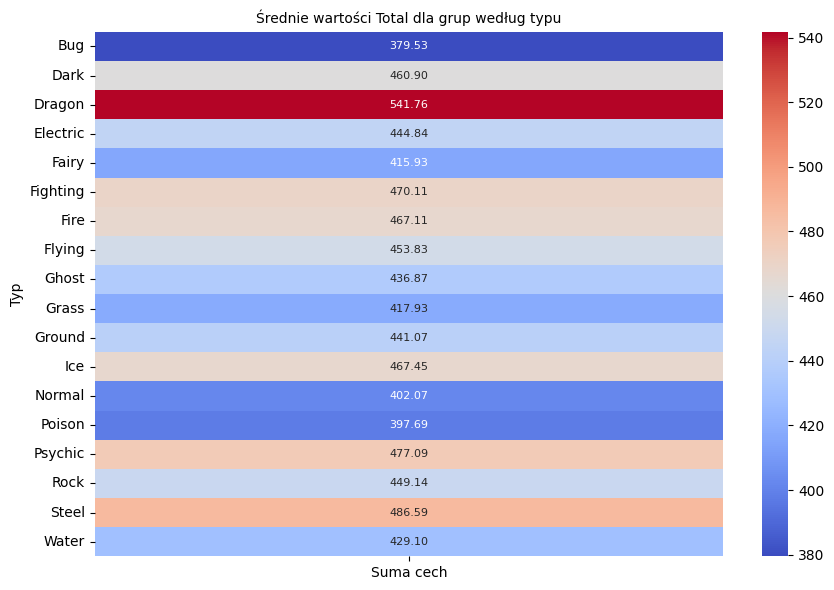

In [19]:
plt.figure(figsize=(9, 6))
#Oddzielnie wyświetlamy heatmapę dla średnich wartości Total dla grup według typu
sns.heatmap(srednie_dane[[ 'Total']].rename(columns=nazwy_cech), yticklabels=srednie_dane['Typ'], xticklabels=True,
             cmap='coolwarm', fmt=".2f", annot=True, annot_kws={"size": 8})
plt.title("Średnie wartości Total dla grup według typu", fontsize=10)
plt.ylabel('Typ')
plt.tight_layout()
plt.show()

W grupach uwzględniających oba typy Dragon ma najwyższą średnią `Total` (541,76) i ataku (105,76). Bug ma najniższą średnią `Total` (379,53), a Steel najwyższą średnią obronę (116,61).

Te wyniki dotyczą średnich grup, a nie każdego Pokémona osobno. Jeden Pokémon może należeć do dwóch porównywanych grup. Sprawdzimy też mediany i rozrzut obrony.

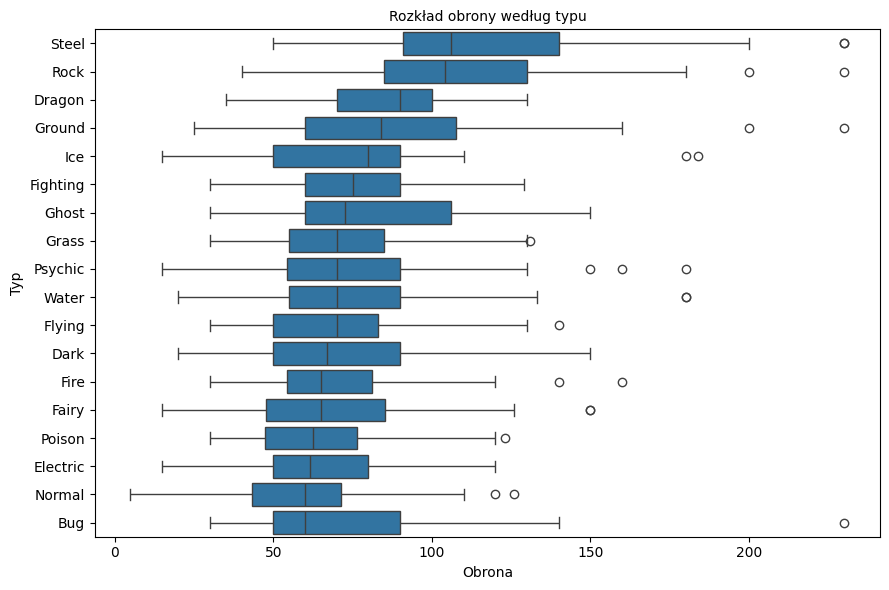

In [20]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=dane_typy, y="Typ", x="Defense",
             order=dane_typy.groupby('Typ')['Defense'].median().sort_values(ascending=False).index)
plt.title("Rozkład obrony według typu", fontsize = 10)
plt.xlabel('Obrona')
plt.ylabel('Typ')
plt.tight_layout()
plt.show()


Steel ma najwyższą medianę obrony (106), a Rock niewiele niższą (104). Wysoka średnia dla Steel nie wynika więc wyłącznie z pojedynczych dużych wartości. Nie oznacza to jednak, że każdy Pokémon mający typ Steel ma wyższą obronę od pozostałych.

Porównamy trzy typy o najwyższej średniej `Total`: Dragon, Steel i Psychic. Każdy typ pokazujemy na osobnym panelu, aby punkty różnych grup nie zasłaniały się nawzajem. W obrębie jednego panelu każdy wpis pojawia się raz. Rozmiar punktu pokazuje `Total`.

Pokémon z dwoma wybranymi typami występuje na obu odpowiednich panelach. Nadal jest to ten sam Pokémon. Na jednym panelu punkty różnych wpisów o takich samych wartościach również mogą się nakładać.

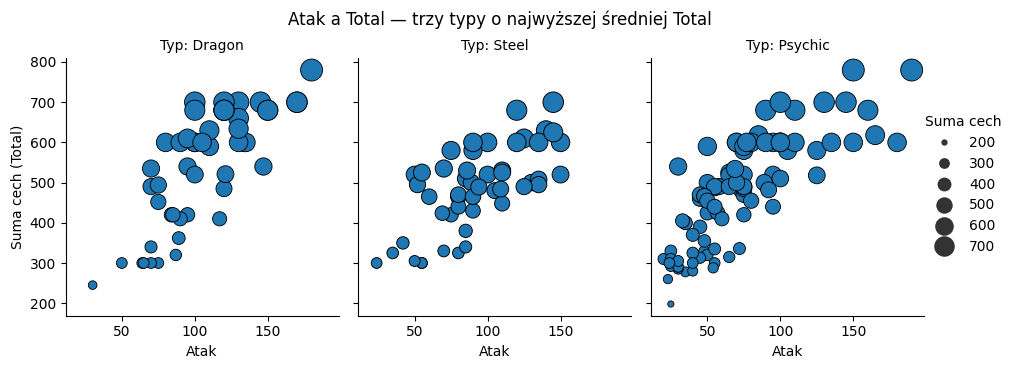

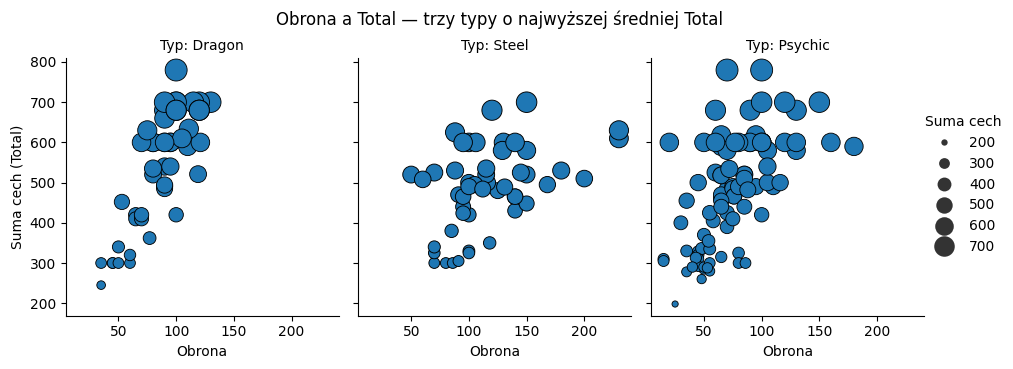

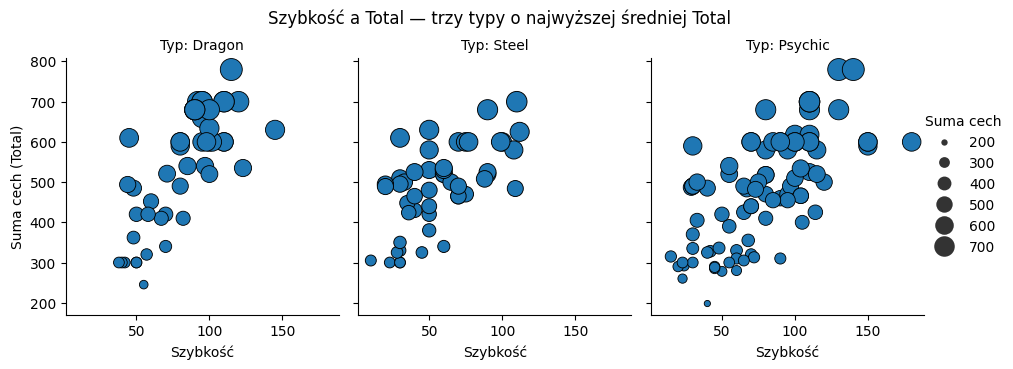

In [21]:
# Osobny panel dla każdego typu, żeby grupy się nie zasłaniały
trzy_typy_o_najwyzszej_sredniej = dane_typy.groupby('Typ')['Total'].mean().nlargest(3)
dane_wyfiltrowane = dane_typy[dane_typy['Typ'].isin(trzy_typy_o_najwyzszej_sredniej.index)]
for cecha in ['Attack', 'Defense', 'Speed']:
    wykres = sns.relplot(data=dane_wyfiltrowane, x=cecha, y='Total',
                        col='Typ', col_order=trzy_typy_o_najwyzszej_sredniej.index,
                        size='Total', sizes=(20, 250), height=3.5, aspect=0.9,
                        edgecolor='black')
    wykres.set_axis_labels(nazwy_cech[cecha], 'Suma cech (Total)')
    wykres.legend.set_title('Suma cech')
    wykres.set_titles('Typ: {col_name}')
    wykres.figure.suptitle(f'{nazwy_cech[cecha]} a Total — trzy typy o najwyższej średniej Total', y=1.04)
    plt.show()

Spośród tych trzech grup Dragon ma najwyższy średni atak i szybkość, a Steel najwyższą średnią obronę. Punkty pokazują też różnice wewnątrz grup — pojedynczy Pokémon z innej grupy może mieć wyższą wartość cechy.

Grupy częściowo obejmują te same Pokémony. Wykres nie dzieli całego zbioru na trzy rozłączne części.

Sprawdzimy, ile wpisów ma każdy typ. Bierzemy pod uwagę oba typy, ale jeden wpis liczymy najwyżej raz dla danego typu.

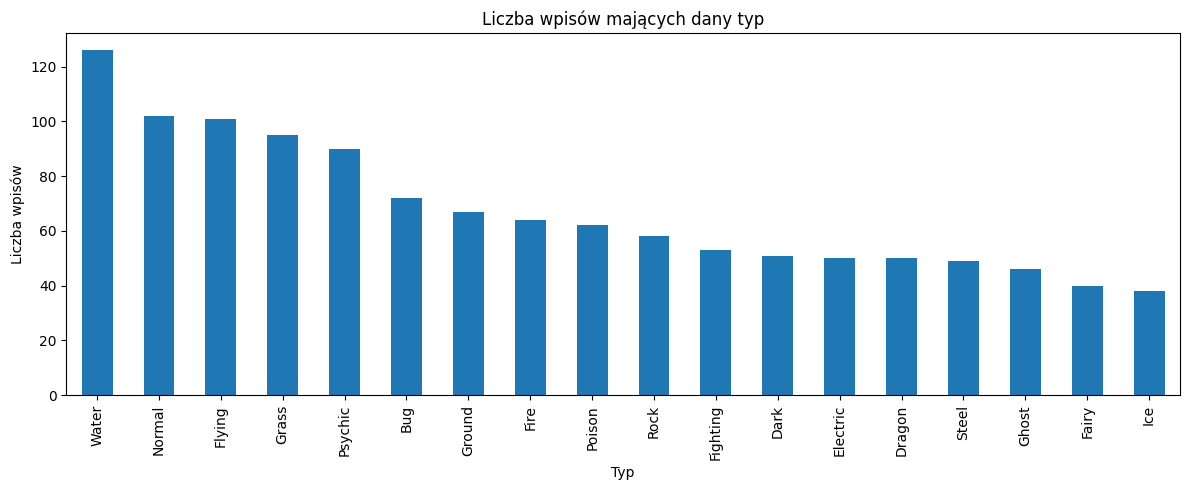

In [22]:
# Liczymy każdy wpis raz dla każdego jego typu
dane_typy['Typ'].value_counts().plot(kind='bar', figsize=(12, 5))
plt.title('Liczba wpisów mających dany typ')
plt.xlabel('Typ')
plt.ylabel('Liczba wpisów')
plt.tight_layout()
plt.show()

Najmniej wpisów ma typ Ice (38), a najwięcej Water (126). Flying ma 101 wpisów: 4 z Flying jako pierwszym typem i 97 z Flying jako drugim typem.

Są to liczby Pokémonów mających dany typ w tym zbiorze. Pokémon dwutypowy należy do dwóch grup, ale nadal jest jednym wpisem. W całym pliku jest 800 wpisów: 386 jednotypowych i 414 dwutypowych.

## 5. Porównanie generacji

Sprawdzimy średnie cech oraz średnią i medianę `Total` w każdej generacji. Używamy pierwotnego zbioru 800 wpisów. Pokémon dwutypowy jest liczony raz, tak samo jak jednotypowy.

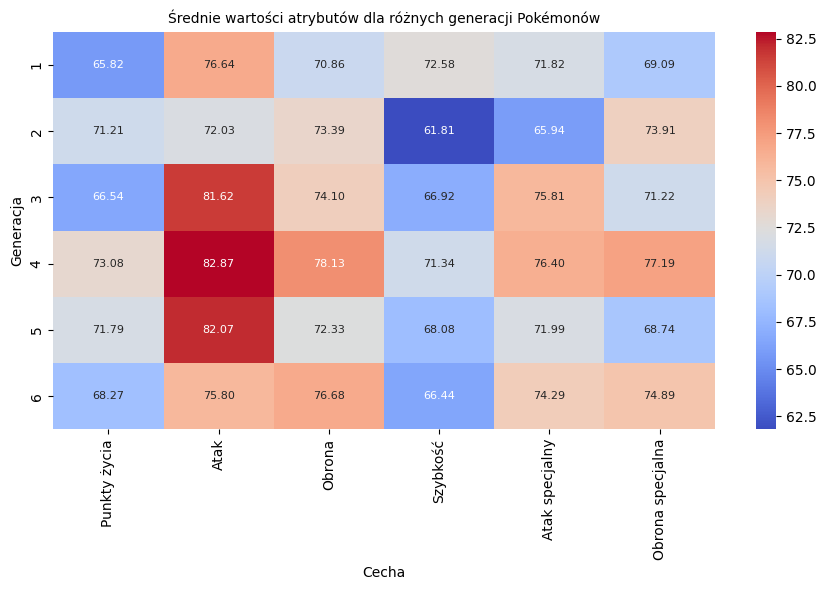

In [23]:
plt.figure(figsize=(9, 6))
srednie_wedlug_generacji = dane.groupby('Generation')[kolumny_statystyk].mean().reset_index()
sns.heatmap(srednie_wedlug_generacji[['HP', 'Attack', 'Defense', 'Speed', 'Sp. Atk', 'Sp. Def']].rename(columns=nazwy_cech),
             yticklabels=srednie_wedlug_generacji['Generation'], 
             xticklabels=True, cmap='coolwarm', fmt=".2f", annot=True, annot_kws={"size": 8})
plt.title("Średnie wartości atrybutów dla różnych generacji Pokémonów", fontsize=10)
plt.xlabel('Cecha')
plt.ylabel('Generacja')
plt.tight_layout()
plt.show()

Wartości średnie różnią się między generacjami. Generacje 3, 4 i 5 wyróżniają się średnim atakiem, a generacja 2 ma najniższą średnią szybkość. Sprawdzimy teraz, która generacja ma najwyższą średnią i medianę `Total`. To porównanie statystyk, a nie ocena tego, która generacja jest najlepsza w grze.

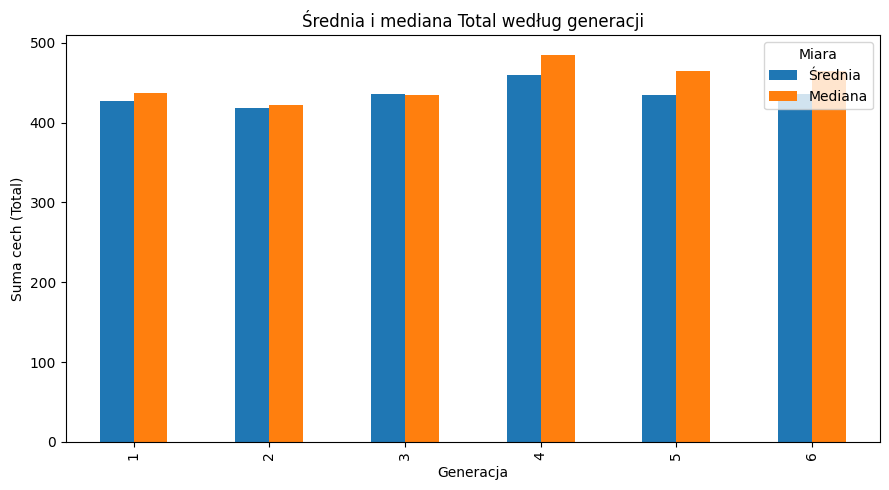

In [24]:
# Porównujemy średnią i medianę Total w każdej generacji
statystyki_generacji = dane.groupby('Generation')['Total'].agg(Średnia='mean', Mediana='median')
statystyki_generacji.plot(kind='bar', figsize=(9, 5))
plt.title('Średnia i mediana Total według generacji')
plt.xlabel('Generacja')
plt.ylabel('Suma cech (Total)')
plt.legend(title='Miara')
plt.tight_layout()
plt.show()

Generacja 4 ma najwyższą średnią `Total` (459,02) i medianę (485) w tym pliku. To porównanie sumy cech w grupach, a nie ocena każdego Pokémona.

Podobna średnia i mediana nie wystarczają do stwierdzenia, że rozkład jest normalny. Poniżej oglądamy rozkład `Total` dla całego zbioru, a nie osobno dla generacji.

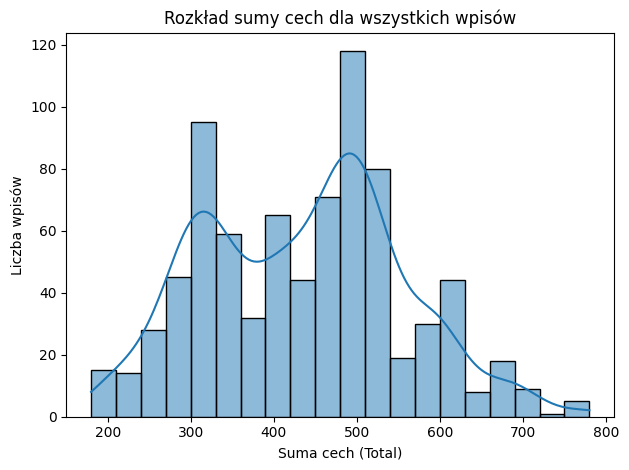

In [25]:
# Oglądamy rozkład sumy cech
sns.histplot(data=dane, x='Total', bins=20, kde=True)
plt.title('Rozkład sumy cech dla wszystkich wpisów')
plt.xlabel('Suma cech (Total)')
plt.ylabel('Liczba wpisów')
plt.tight_layout()
plt.show()

### Wnioskowanie statystyczne — Total według generacji

Porównujemy średnie w sześciu generacjach na zbiorze form referencyjnych z sekcji 2. ANOVA Welcha dopuszcza nierówne wariancje. Jeżeli wynik ogólny jest istotny, test Gamesa–Howella wskazuje różniące się pary generacji z uwzględnieniem wielokrotnych porównań.

Hipoteza zerowa zakłada równość średnich w sześciu generacjach. Oglądamy wykresy Q–Q w grupach, a w tabeli podajemy ich liczebności i odchylenia standardowe. Odchylenia od normalności uwzględniamy w interpretacji. Test Welcha stosujemy jako przybliżenie przy tych liczebnościach i z ograniczeniem niezależności gatunków opisanym we wprowadzeniu.

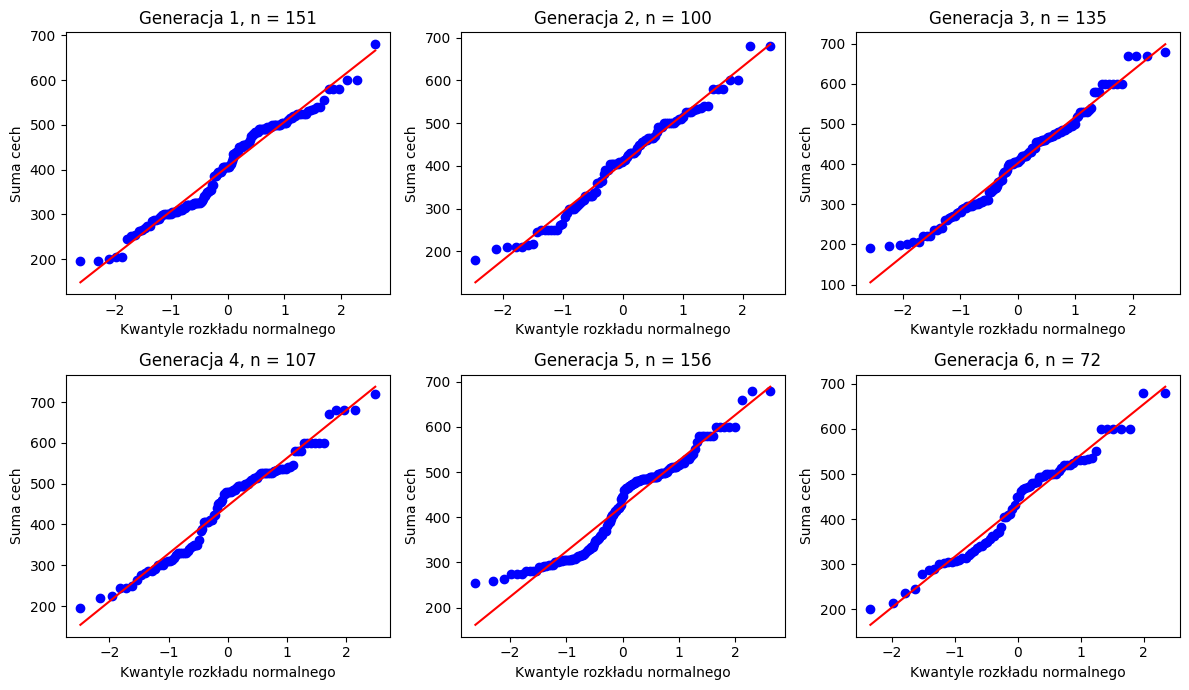

In [26]:
fig, osie = plt.subplots(2, 3, figsize=(12, 7))
for os, (generacja, grupa) in zip(osie.flat, dane_bazowe.groupby("Generation")):
    stats.probplot(grupa["Total"], dist="norm", plot=os)
    os.set(title=f"Generacja {generacja}, n = {len(grupa)}",
           xlabel="Kwantyle rozkładu normalnego", ylabel="Suma cech")
plt.tight_layout()
plt.show()


In [27]:
grupy_generacji = dane_bazowe.groupby("Generation")["Total"]
print(grupy_generacji.agg(["size", "mean", "std"]).rename(columns={**nazwy_miar, "size": "Liczba gatunków"}).rename_axis("Generacja").round(2).to_string())
poziomy = list(grupy_generacji.groups)
proby = [grupy_generacji.get_group(generacja) for generacja in poziomy]
anova_generacji = stats.f_oneway(*proby, equal_var=False)
print(f"F = {anova_generacji.statistic:.3f}, p = {anova_generacji.pvalue:.6g}")

if anova_generacji.pvalue < 0.05:
    games_howell = stats.tukey_hsd(*proby, equal_var=False)
    porownania = pd.DataFrame(
        [(a, b, games_howell.statistic[i, j], games_howell.pvalue[i, j])
         for i, a in enumerate(poziomy)
         for j, b in enumerate(poziomy) if i < j],
        columns=["Generacja A", "Generacja B", "Różnica średnich (A − B)", "Skorygowana wartość p"],
    )
    print(porownania.round(4).to_string(index=False))


           Liczba gatunków  Średnia  Odchylenie standardowe
Generacja                                                  
1                      151   407.08                   99.74
2                      100   406.18                  112.29
3                      135   402.06                  115.18
4                      107   445.76                  117.48
5                      156   425.31                  102.27
6                       72   429.58                  111.93
F = 2.583, p = 0.0263085
 Generacja A  Generacja B  Różnica średnich (A − B)  Skorygowana wartość p
           1            2                    0.8995                 1.0000
           1            3                    5.0202                 0.9988
           1            4                  -38.6775                 0.0664
           1            5                  -18.2282                 0.6118
           1            6                  -22.5039                 0.6946
           2            3                    

Średnie `Total` różnią się między generacjami w teście Welcha (p = 0,0263). Spośród 15 par pokoleń tylko porównanie III–IV osiąga próg 0,05 w teście Gamesa–Howella. Generacja IV ma średnio o **43,70 pkt** więcej niż III (p skorygowane = 0,0468).

## 6. Pokémony legendarne

Status legendarny jest osobną cechą. Zarówno Pokémon jednotypowy, jak i dwutypowy może być legendarny lub zwykły.

W kolumnie `Legendary` wartość `True` oznacza status legendarny, a `False` zwykły. Na wykresach używamy nazw „Legendarny” i „Zwykły”. W zbiorze jest 65 wpisów legendarnych i 735 zwykłych — razem 800. Przy tym porównaniu każdy wpis liczymy raz.

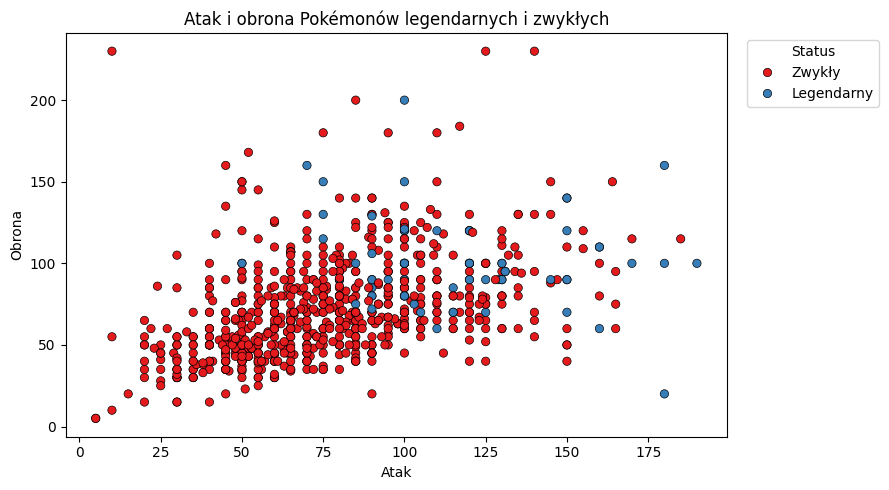

In [28]:
# Porównujemy atak i obronę obu grup
plt.figure(figsize=(9, 5))
sns.scatterplot(data=dane, x='Attack', y='Defense',
                hue=dane['Legendary'].map({False: 'Zwykły', True: 'Legendarny'}).rename('Status'),
                palette='Set1', edgecolor='black')
plt.xlabel('Atak')
plt.ylabel('Obrona')
plt.title('Atak i obrona Pokémonów legendarnych i zwykłych')
plt.legend(title='Status', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

Wśród legendarnych wpisów widać wiele wysokich wartości ataku i obrony, ale podobne wartości występują też u zwykłych Pokémonów. Sam atak lub obrona nie wystarczają więc do rozpoznania statusu legendarnego. Wykres pokazuje obie grupy razem, bez podziału na typy.

### Związek typu ze statusem legendarnym — 721 gatunków

Dla każdego typu zestawiamy jego posiadanie ze statusem legendarnym w tabeli 2 × 2. Używamy jednej formy na każdy z 721 gatunków i uwzględniamy oba typy. Hipoteza zerowa zakłada niezależność posiadania typu i statusu legendarnego, a alternatywna związek między nimi.

V Craméra mierzy siłę związku. Dwustronny dokładny test Fishera działa również przy zerowej liczebności w komórce. Stosujemy korektę Holma dla 18 porównań i próg istotności 0,05. Odsetki w dwóch grupach pokazują kierunek różnicy. Wyniki interpretujemy przy założeniu niezależności obserwacji.


In [29]:
# Dla każdego typu porównujemy gatunki mające ten typ z pozostałymi.
typy = sorted(pd.concat([dane_bazowe["Type 1"], dane_bazowe["Type 2"]]).dropna().unique())
wyniki_v = []
for typ in typy:
    ma_typ = dane_bazowe["Type 1"].eq(typ) | dane_bazowe["Type 2"].eq(typ)
    tabela_v = pd.crosstab(ma_typ, dane_bazowe["Legendary"])
    wyniki_v.append({
        "Typ": typ,
        "Gatunki danego typu": tabela_v.loc[True].sum(),
        "Legendarne danego typu": tabela_v.loc[True, True],
        "Legendarne wśród danego typu (%)": 100 * tabela_v.loc[True, True] / tabela_v.loc[True].sum(),
        "Legendarne wśród pozostałych (%)": 100 * tabela_v.loc[False, True] / tabela_v.loc[False].sum(),
        "V Craméra": association(tabela_v, method="cramer"),
        "Wartość p": stats.fisher_exact(tabela_v).pvalue,
    })
wyniki_v = pd.DataFrame(wyniki_v).sort_values("Wartość p").reset_index(drop=True)
# Korekta Holma zachowuje rosnącą kolejność skorygowanych wartości p.
mnozniki = np.arange(len(wyniki_v), 0, -1)
wyniki_v["p po korekcie Holma"] = (wyniki_v["Wartość p"] * mnozniki).cummax().clip(upper=1)
wyniki_v["Istotna przy 0,05"] = wyniki_v["p po korekcie Holma"].lt(0.05).map({True: "Tak", False: "Nie"})
wyniki_v = wyniki_v.sort_values("V Craméra", ascending=False).reset_index(drop=True)
display(wyniki_v.round({
    "V Craméra": 3, "Wartość p": 6, "p po korekcie Holma": 6,
    "Legendarne wśród danego typu (%)": 2, "Legendarne wśród pozostałych (%)": 2,
}))


,Typ,Gatunki danego typu,Legendarne danego typu,Legendarne wśród danego typu (%),Legendarne wśród pozostałych (%),V Craméra,Wartość p,p po korekcie Holma,"Istotna przy 0,05"
0,Dragon,38,10,26.32,5.27,0.192,0.000052,0.000929,Tak
1,Psychic,74,11,14.86,5.41,0.117,0.004377,0.074413,Nie
2,Bug,66,0,0.00,7.02,0.083,0.016266,0.260251,Nie
3,Poison,59,0,0.00,6.95,0.078,0.026004,0.390064,Nie
4,Flying,90,10,11.11,5.71,0.073,0.062703,0.877849,Nie
5,Fire,56,7,12.50,5.86,0.073,0.078201,0.938414,Nie
6,Normal,97,2,2.06,7.05,0.070,0.071991,0.935882,Nie
7,Grass,84,2,2.38,6.91,0.059,0.151478,1.000000,Nie
8,Steel,41,5,12.20,6.03,0.058,0.173947,1.000000,Nie
9,Water,118,4,3.39,6.97,0.054,0.213834,1.000000,Nie


Po korekcie Holma istotny związek ze statusem legendarnym wykazał tylko typ Dragon (p około 0,000929). Dla Bug mamy 0 legendarnych gatunków, V Craméra około 0,083, p około 0,0163 i p po korekcie około 0,2603.

### Liczebność i odsetki według typu — 800 wpisów

Wracamy do wszystkich 800 wpisów, obejmujących dodatkowe formy. Każdy wiersz kolejnej tabeli i wykresu dotyczy wpisów mających dany typ. W teście Dragon obejmuje 10 legendarnych spośród 38 gatunków, a w pełnym zbiorze 16 legendarnych spośród 50 wpisów. Pokémon dwutypowy jest uwzględniony w dwóch grupach, raz w każdej z nich.


Liczebności według typu — zbiór 800 wpisów


Status,Zwykły,Legendarny,Razem
Typ,,,
Bug,72,0,72
Dark,48,3,51
Dragon,34,16,50
Electric,45,5,50
Fairy,37,3,40
Fighting,49,4,53
Fire,56,8,64
Flying,86,15,101
Ghost,43,3,46


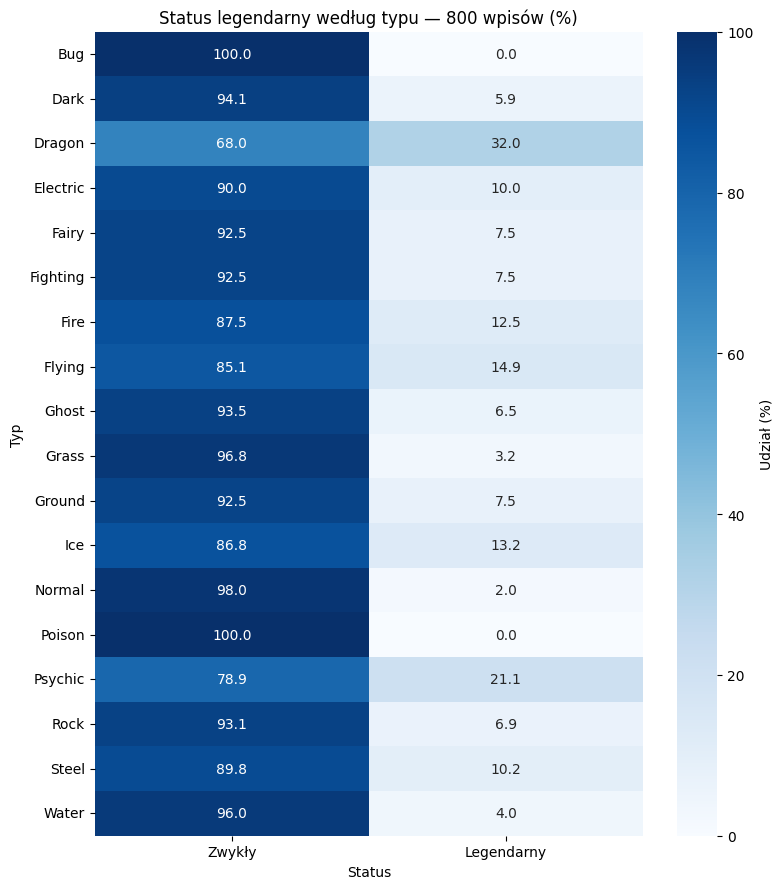

In [30]:
# Pokazujemy liczby i procenty osobno
tabela = pd.crosstab(dane_typy['Typ'], dane_typy['Legendary']).reindex(columns=[False, True], fill_value=0)
tabela_liczb = tabela.rename(columns={False: 'Zwykły', True: 'Legendarny'})
tabela_liczb['Razem'] = tabela_liczb.sum(axis=1)
print("Liczebności według typu — zbiór 800 wpisów")
display(tabela_liczb.rename_axis("Status", axis="columns"))
tabela_proc = tabela.div(tabela.sum(axis=1), axis=0) * 100
tabela_proc = tabela_proc.rename(columns={False: 'Zwykły', True: 'Legendarny'})
plt.figure(figsize=(8, 9))
sns.heatmap(tabela_proc, annot=True, fmt='.1f', vmin=0, vmax=100,
            cmap='Blues', cbar_kws={'label': 'Udział (%)'})
plt.title('Status legendarny według typu — 800 wpisów (%)')
plt.xlabel('Status')
plt.ylabel('Typ')
plt.tight_layout()
plt.show()

Najwyższy procent legendarnych wpisów mają grupy Dragon (16 z 50, czyli 32%), Psychic (19 z 90, czyli 21,1%) i Flying (15 ze 101, czyli 14,9%). Najwięcej legendarnych wpisów liczbowo ma Psychic: 19.

Uwzględniamy oba typy. Legendarny Pokémon Psychic/Flying należy do grupy Psychic i Flying. W każdej grupie liczymy go raz, ale w całym zbiorze nadal jest jednym wpisem. Nie dodajemy więc liczebności tych grup, aby ustalić liczbę legendarnych w całym pliku. W całym zbiorze jest 65 legendarnych wpisów.

## 7. Jak zmieniają się statystyki podczas ewolucji?

Porównujemy kompletne, nierozgałęzione trzyetapowe linie ewolucyjne w generacjach I–VI. Mapa numerów Pokédexu pochodzi z [PokeAPI](https://github.com/PokeAPI/pokeapi/blob/cd5f6c6232f23430aa6089896d96230f5f7ecef4/data/v2/csv/pokemon_species.csv). Relacje pochodzenia ustalają kolejność etapów. Korzystamy z jednej formy referencyjnej na gatunek, wybranej w sekcji 2, oraz ze statystyk zapisanych w `pokemon.csv`. Każda linia stanowi jedną jednostkę analizy. Na jej kolejnych etapach porównujemy statystyki gatunków, na przykład Charmandera, Charmeleona i Charizarda.

W notebooku zapisaliśmy zestawienie PokeAPI użyte 22 listopada 2026 r. dla generacji I–VI. Listy `linie_ewolucyjne` (sekcja 7) i `koncowe_id` (sekcja 8) zawierają dokładne identyfikatory wykorzystane w obliczeniach. Można je odtworzyć bez pobierania danych z internetu. Skrót SHA-256 obu list w zapisie JSON bez spacji: `871663186c7548486b33c6dfa71cb55b1de572065b99a9631daca9cfdb6b7bf1`.

In [31]:
# Kolejność w każdej krotce odpowiada relacjom rodzic–potomek w PokeAPI.
linie_ewolucyjne = [
    (1,2,3), (4,5,6), (7,8,9), (10,11,12), (13,14,15), (16,17,18),
    (172,25,26), (29,30,31), (32,33,34), (173,35,36), (174,39,40), (41,42,169),
    (63,64,65), (66,67,68), (69,70,71), (74,75,76), (81,82,462), (92,93,94),
    (111,112,464), (440,113,242), (116,117,230), (239,125,466), (240,126,467),
    (137,233,474), (147,148,149), (152,153,154), (155,156,157), (158,159,160),
    (175,176,468), (179,180,181), (298,183,184), (187,188,189), (220,221,473),
    (246,247,248), (252,253,254), (255,256,257), (258,259,260), (270,271,272),
    (273,274,275), (287,288,289), (293,294,295), (304,305,306), (406,315,407),
    (328,329,330), (355,356,477), (363,364,365), (371,372,373), (374,375,376),
    (387,388,389), (390,391,392), (393,394,395), (396,397,398), (403,404,405),
    (443,444,445), (495,496,497), (498,499,500), (501,502,503), (506,507,508),
    (519,520,521), (524,525,526), (532,533,534), (535,536,537), (540,541,542),
    (543,544,545), (551,552,553), (574,575,576), (577,578,579), (582,583,584),
    (599,600,601), (602,603,604), (607,608,609), (610,611,612), (633,634,635),
    (650,651,652), (653,654,655), (656,657,658), (661,662,663), (664,665,666),
    (669,670,671), (679,680,681), (704,705,706),
]
mapa_ewolucji = pd.DataFrame(
    [(linia[0], etap, numer) for linia in linie_ewolucyjne
     for etap, numer in enumerate(linia, start=1)],
    columns=["Linia", "Etap", "#"],
)
ewolucje = mapa_ewolucji.merge(dane_bazowe, on="#", how="left", validate="one_to_one")
assert ewolucje[["Total", *cechy]].notna().all().all(), "Brak statystyk dla gatunku z mapy"
total_etapy = ewolucje.pivot(index="Linia", columns="Etap", values="Total")
przyrost_1 = total_etapy[2] - total_etapy[1]
przyrost_2 = total_etapy[3] - total_etapy[2]
print(f"Liczba linii: {len(total_etapy)}")
display(total_etapy.agg(["mean", "median", "std"]).rename(index=nazwy_miar)
        .rename_axis("Miara sumy cech").round(2))


Liczba linii: 81


Etap,1,2,3
Miara sumy cech,,,
Średnia,286.63,391.14,518.99
median,300.00,405.00,525.00
Odchylenie standardowe,39.91,57.13,44.25


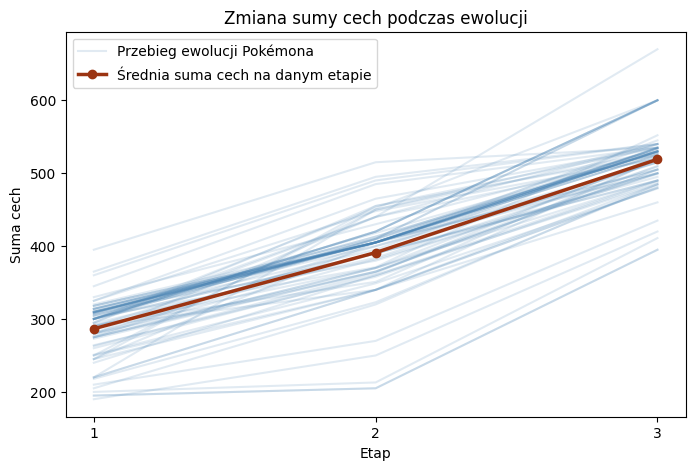

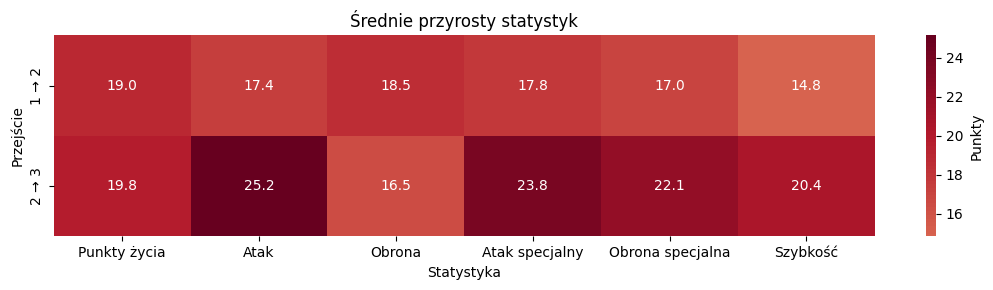

In [32]:
fig, ax = plt.subplots(figsize=(8, 5))
linie_na_wykresie = ax.plot(total_etapy.columns, total_etapy.to_numpy().T, color="steelblue", alpha=.16)
linie_na_wykresie[0].set_label("Przebieg ewolucji Pokémona")
ax.plot(total_etapy.columns, total_etapy.mean(), "o-", color="#9b3412",
        linewidth=2.5, label="Średnia suma cech na danym etapie")
ax.set(xticks=[1, 2, 3], xlabel="Etap", ylabel="Suma cech",
       title="Zmiana sumy cech podczas ewolucji")
ax.legend()
plt.show()

srednie_przyrosty = (
    ewolucje.sort_values(["Linia", "Etap"])
    .groupby("Linia")[cechy].diff()
    .groupby(ewolucje["Etap"]).mean().dropna(how="all")
    .rename(index={2: "1 → 2", 3: "2 → 3"}, columns=nazwy_cech)
)
fig, ax = plt.subplots(figsize=(11, 3))
sns.heatmap(srednie_przyrosty, annot=True, fmt=".1f", cmap="RdBu_r",
            center=0, cbar_kws={"label": "Punkty"}, ax=ax)
ax.set(xlabel="Statystyka", ylabel="Przejście", title="Średnie przyrosty statystyk")
plt.tight_layout()
plt.show()


Porównujemy 81 ciągów ewolucyjnych, każdy obejmujący trzy etapy. Niebieska linia pokazuje sumę cech na kolejnych etapach ewolucji, a czerwona średnią na każdym etapie.

Po pierwszej ewolucji najbardziej rosną średnio punkty życia (+18,98 pkt) i obrona (+18,53 pkt). Po drugiej największy przyrost mają atak (+25,16 pkt) i atak specjalny (+23,84 pkt). Obrona rośnie wtedy średnio o 16,51 pkt. Większy przyrost całkowity rozkłada się więc nierównomiernie na poszczególne cechy.

### Wnioskowanie statystyczne

- W teście t dla prób zależnych H₀ zakłada, że średnia różnica między drugim a pierwszym przyrostem wynosi 0. H₁ zakłada różnicę od 0.
- W ANOVA z powtarzanymi pomiarami H₀ zakłada równość średnich `Total` na trzech etapach. H₁ zakłada, że co najmniej dwie średnie się różnią. Korekta Greenhouse’a–Geissera uwzględnia możliwość nierównych wariancji różnic między parami etapów.

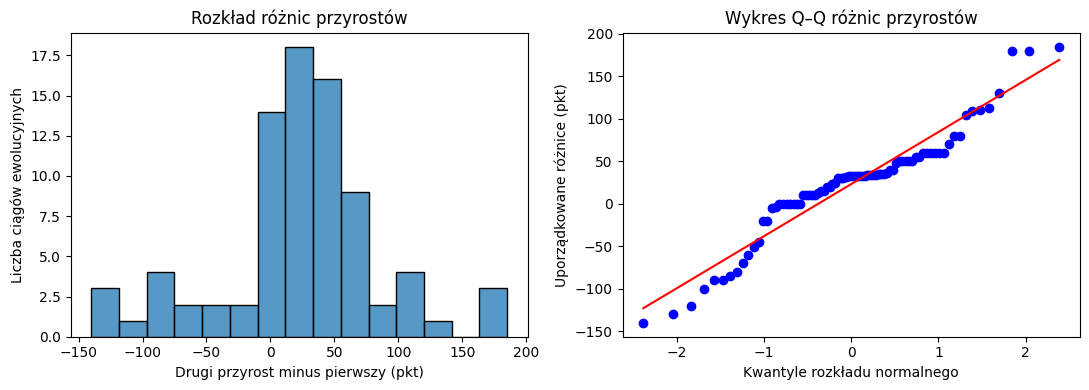

Test Shapiro–Wilka dla różnic przyrostów, p = 0.00031183
95% bootstrapowy PU średniej różnicy przyrostów = [9.55, 36.64] pkt


In [33]:
# Porównujemy drugi i pierwszy przyrost w obrębie każdej linii.
roznice_przyrostow = przyrost_2 - przyrost_1
fig, osie = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(roznice_przyrostow, bins=15, ax=osie[0])
osie[0].set(title="Rozkład różnic przyrostów", xlabel="Drugi przyrost minus pierwszy (pkt)",
            ylabel="Liczba ciągów ewolucyjnych")
stats.probplot(roznice_przyrostow, dist="norm", plot=osie[1])
osie[1].set(title="Wykres Q–Q różnic przyrostów", xlabel="Kwantyle rozkładu normalnego",
            ylabel="Uporządkowane różnice (pkt)")
plt.tight_layout()
plt.show()
test_normalnosci_roznic = stats.shapiro(roznice_przyrostow)
print(f"Test Shapiro–Wilka dla różnic przyrostów, p = {test_normalnosci_roznic.pvalue:.6g}")
# Losujemy całe linie, zachowując powiązanie między etapami.
bootstrap_roznicy = stats.bootstrap(
    (roznice_przyrostow.to_numpy(),), np.mean,
    confidence_level=0.95, n_resamples=10000, method="BCa",
    rng=np.random.default_rng(20261122),
)
print(f"95% bootstrapowy PU średniej różnicy przyrostów = "
      f"[{bootstrap_roznicy.confidence_interval.low:.2f}, "
      f"{bootstrap_roznicy.confidence_interval.high:.2f}] pkt")


Rozkład różnic przyrostów odbiega od normalnego. Test Shapiro–Wilka daje p około 0,00031. Wykres Q–Q pokazuje odstępstwa, a histogram pozwala ocenić rozrzut i wartości skrajne. Przy 81 ciągach ewolucyjnych zachowujemy test t jako przybliżenie i uzupełniamy ocenę bootstrapowym przedziałem ufności dla średniej. Losowanie całych linii zachowuje powiązanie etapów. Bootstrap zakłada niezależność między liniami. Korekta Greenhouse’a–Geissera w ANOVA dotyczy sferyczności. Rozkład obserwacji i niezależność linii również wpływają na interpretację.

Bootstrapowy 95% przedział ufności dla średniej różnicy przyrostów wynosi 9,55–36,64 pkt. Cały przedział leży powyżej zera i wspiera wniosek o większym drugim przyroście.

In [34]:
test_przyrostow = stats.ttest_rel(przyrost_2, przyrost_1)
przedzial_przyrostow = test_przyrostow.confidence_interval()
roznica_przyrostow = (przyrost_2 - przyrost_1).mean()
print(f"Średnie przyrosty: {przyrost_1.mean():.2f} i {przyrost_2.mean():.2f} pkt")
print(f"Różnica: {roznica_przyrostow:.2f} pkt, "
      f"95% PU [{przedzial_przyrostow.low:.2f}, {przedzial_przyrostow.high:.2f}], "
      f"t = {test_przyrostow.statistic:.2f}, p = {test_przyrostow.pvalue:.4g}")

# Jednoczynnikowa ANOVA dla kompletnej macierzy linia × etap.
macierz = total_etapy.to_numpy()
n_linii, n_etapow = macierz.shape
srednia_ogolna = macierz.mean()
srednie_etapow = macierz.mean(axis=0)
reszty = macierz - macierz.mean(axis=1, keepdims=True) - srednie_etapow + srednia_ogolna
ss_etap = n_linii * ((srednie_etapow - srednia_ogolna) ** 2).sum()
ss_reszt = (reszty ** 2).sum()
df_etap = n_etapow - 1
df_reszt = (n_linii - 1) * df_etap
f_ewolucja = (ss_etap / df_etap) / (ss_reszt / df_reszt)

# Epsilon GG z macierzy kowariancji wycentrowanej po etapach.
kowariancja = np.cov(macierz, rowvar=False)
centrowanie = np.eye(n_etapow) - np.ones((n_etapow, n_etapow)) / n_etapow
kowariancja_centrowana = centrowanie @ kowariancja @ centrowanie
epsilon = np.trace(kowariancja_centrowana) ** 2 / (
    df_etap * np.trace(kowariancja_centrowana @ kowariancja_centrowana)
)
df1_gg, df2_gg = epsilon * df_etap, epsilon * df_reszt
p_gg = stats.f.sf(f_ewolucja, df1_gg, df2_gg)
print(f"ANOVA powtarzana: F({df1_gg:.2f}, {df2_gg:.2f}) = {f_ewolucja:.2f}, "
      f"p = {p_gg:.4g}, epsilon GG = {epsilon:.3f}")


Średnie przyrosty: 104.51 i 127.85 pkt
Różnica: 23.35 pkt, 95% PU [9.55, 37.15], t = 3.37, p = 0.001172
ANOVA powtarzana: F(1.98, 158.18) = 1555.13, p = 2.138e-104, epsilon GG = 0.989


W badanych liniach średni przyrost wyniósł **104,51 pkt** po pierwszej ewolucji i **127,85 pkt** po drugiej. Drugi przyrost był średnio o **23,35 pkt** większy (95% PU 9,55–37,15; p = 0,00117). Był większy w 58 z 81 linii. ANOVA z korektą Greenhouse’a–Geissera wykazała różnicę średniego Total między etapami (p = 2,14e-104). Wnioski dotyczą linii spełniających kryteria analizy i statystyk zapisanych w tym katalogu.

## 8. Końcowe formy i Pokémony bez ewolucji

Porównujemy po jednej formie referencyjnej na gatunek. W każdej gałęzi bierzemy gatunek, który nie ma dalszej ewolucji **w pokoleniach I–VI**. Uwzględniamy wszystkie końcowe gałęzie rodziny oraz gatunki bez żadnego poprzednika ani następcy. Podział na 0, 1 lub 2 ewolucje wynika z liczby przejść od początku gałęzi. Źródłem mapy jest [PokeAPI](https://github.com/PokeAPI/pokeapi/blob/cd5f6c6232f23430aa6089896d96230f5f7ecef4/data/v2/csv/pokemon_species.csv). Późniejsze generacje mogą zmieniać klasyfikację. Przykładowo Farfetch’d zalicza się tu do gatunków bez ewolucji.

Każdy końcowy gatunek ma taką samą wagę w zestawieniu, więc rodziny z kilkoma gałęziami wnoszą kilka obserwacji. Porównanie ma charakter opisowy. Wyniki pokazujemy również dla gatunków oznaczonych w CSV jako nielegendarne, aby zobaczyć, jak skład grup wpływa na porównanie.

Grupy po zerowej, jednej i dwóch ewolucjach obejmują różne gatunki. Różnice ich średnich opisują przekrój grup i zależą od ich składu. Zmiany między kolejnymi etapami oceniamy w sekcji 7, w dopasowanych ciągach ewolucyjnych.

In [35]:
koncowe_id = {
    0: (83,115,127,128,131,132,142,144,145,146,150,151,201,203,206,211,213,214,222,225,227,234,235,241,243,244,245,249,250,251,302,303,311,312,313,314,324,327,335,336,337,338,351,352,357,359,369,370,377,378,379,380,381,382,383,384,385,386,417,441,442,455,479,480,481,482,483,484,485,486,487,488,489,490,491,492,493,494,531,538,539,550,556,561,587,594,615,618,621,626,631,632,638,639,640,641,642,643,644,645,646,647,648,649,676,701,702,703,707,716,717,718,719,720,721),
    1: (20,22,24,28,38,47,49,51,53,55,57,59,73,78,80,85,87,89,91,97,99,101,103,105,106,107,110,119,121,122,124,130,134,135,136,139,141,143,162,164,166,168,171,178,185,192,195,196,197,199,202,205,208,210,212,217,219,224,226,229,232,237,262,264,277,279,284,286,291,292,297,301,308,310,317,319,321,323,326,332,334,340,342,344,346,348,350,354,358,362,367,368,400,402,409,411,413,414,416,419,421,423,424,426,428,429,430,432,435,437,448,450,452,454,457,460,461,463,465,469,470,471,472,476,478,505,510,512,514,516,518,523,528,530,547,549,555,558,560,563,565,567,569,571,573,581,586,589,591,593,596,598,606,614,617,620,623,625,628,630,637,660,668,673,675,678,683,685,687,689,691,693,695,697,699,700,709,711,713,715),
    2: (3,6,9,12,15,18,26,31,34,36,40,45,62,65,68,71,76,94,149,154,157,160,169,181,182,184,186,189,230,242,248,254,257,260,267,269,272,275,282,289,295,306,330,365,373,376,389,392,395,398,405,407,445,462,464,466,467,468,473,474,475,477,497,500,503,508,521,526,534,537,542,545,553,576,579,584,601,604,609,612,635,652,655,658,663,666,671,681,706),
}
mapa_koncowych = pd.DataFrame(
    [(numer, liczba) for liczba, numery in koncowe_id.items() for numer in numery],
    columns=["#", "Ewolucje"],
)
koncowe = mapa_koncowych.merge(dane_bazowe, how="left", on="#", validate="one_to_one")
assert koncowe["Total"].notna().all(), "W statystykach brakuje końcowego gatunku"
nielegendarne = koncowe.loc[~koncowe["Legendary"]]
warianty = {"Wszystkie": koncowe, "Bez legendarnych": nielegendarne}
podsumowanie_koncowych = pd.concat(
    {
        nazwa: tabela.groupby("Ewolucje").agg(
            n=("Total", "size"), Średnia=("Total", "mean"),
            Mediana=("Total", "median"), Legendarne=("Legendary", "sum"),
        )
        for nazwa, tabela in warianty.items()
    }, names=["Zbiór"],
)
display(podsumowanie_koncowych.rename(columns={
    "n": "Liczba gatunków", "Średnia": "Średnia sumy cech", "Mediana": "Mediana sumy cech",
    "Legendarne": "Liczba legendarnych gatunków",
}).rename_axis(["Zbiór", "Liczba ewolucji"]).round(2))


Liczba gatunków  ...  Liczba legendarnych gatunków
Zbiór            Liczba ewolucji                   ...                              
Wszystkie        0                            115  ...                            46
                 1                            180  ...                             0
                 2                             89  ...                             0
Bez legendarnych 0                             69  ...                             0
                 1                            180  ...                             0
                 2                             89  ...                             0

[6 rows x 4 columns]

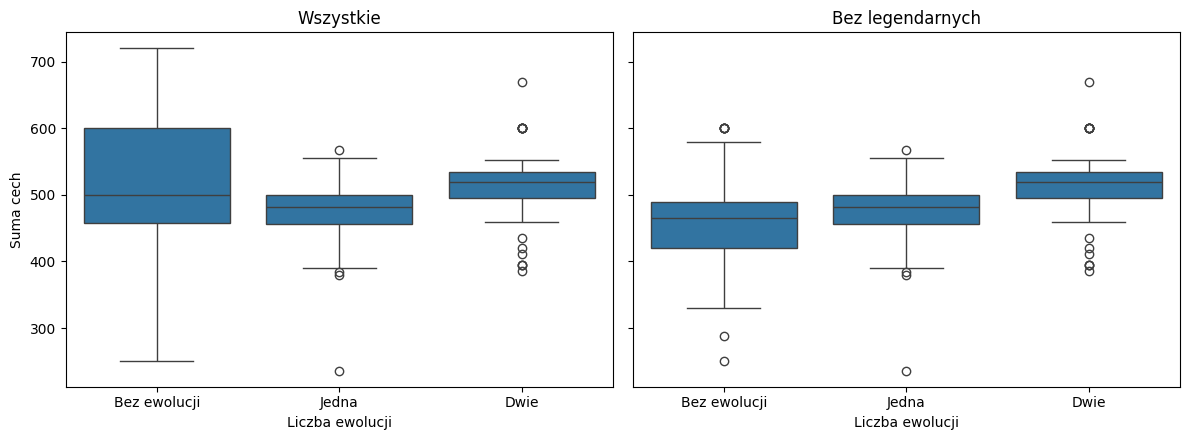

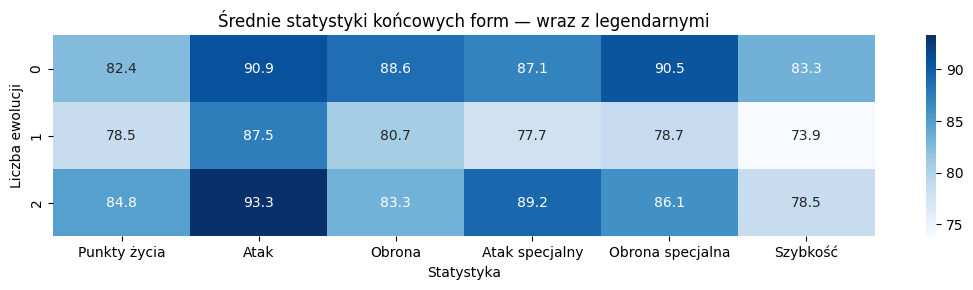

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (nazwa, tabela) in zip(axes, warianty.items()):
    sns.boxplot(data=tabela, x="Ewolucje", y="Total", order=[0, 1, 2], ax=ax)
    ax.set(title=nazwa, xlabel="Liczba ewolucji", ylabel="Suma cech")
    ax.set_xticks([0, 1, 2], ["Bez ewolucji", "Jedna", "Dwie"])
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 3))
srednie_koncowe = koncowe.groupby("Ewolucje")[cechy].mean().rename(columns=nazwy_cech)
sns.heatmap(srednie_koncowe, annot=True, fmt=".1f", cmap="Blues", ax=ax)
ax.set(title="Średnie statystyki końcowych form — wraz z legendarnymi", xlabel="Statystyka", ylabel="Liczba ewolucji")
plt.tight_layout()
plt.show()


to mozna dodac srednie statystki pokemonow bez legendarncych

Pokémony bez ewolucji mają najwyższą średnią `Total` (522,85 pkt). Najwyższą medianę mają gatunki po dwóch ewolucjach (520 pkt wobec 500 pkt w grupie bez ewolucji). Po wyłączeniu 46 gatunków oznaczonych w CSV jako legendarne średnia w grupie bez ewolucji spada do 457,94 pkt, a mediana do 465 pkt. Wtedy najwyższą średnią i medianę mają formy po dwóch ewolucjach.

## 9. Podsumowanie

- **Jeden typ a dwa typy.** Wśród 721 wybranych form gatunków średni Total dla dwutypowych jest wyższy o 28,49 pkt. Test Welcha daje p = 0,000469 i 95% przedział ufności 12,57–44,41 pkt. Bootstrap daje zbliżony przedział 12,63–44,33 pkt. Uzupełniający test rangowy daje p około 0,000482 i dotyczy porównania rozkładów. W pełnym zbiorze 800 wpisów mediany badanych cech są wyższe w grupie dwutypowej.
- **Korelacje i rozkłady.** Najwyższe korelacje między pojedynczymi cechami wynoszą około 0,51. Sześć cech ma dodatnią skośność, największą dla punktów życia i obrony. Korelacja Total z jego składnikami częściowo wynika z definicji sumy.
- **Typy i status legendarny.** W pełnym zbiorze 800 wpisów Dragon ma najwyższą średnią Total i ataku, a Steel najwyższą średnią i medianę obrony. Najwięcej wpisów ma Water (126), najmniej Ice (38). Dragon ma największy odsetek wpisów legendarnych (32%), a Psychic największą ich liczbę (19). W analizie 721 form gatunków po korekcie Holma istotny związek ze statusem legendarnym wykazuje tylko Dragon (p około 0,000929).
- **Generacje.** Wśród 800 wpisów generacja IV ma najwyższą średnią i medianę Total. Dla 721 form gatunków ANOVA Welcha daje p = 0,0263. Spośród 15 par generacji próg 0,05 w teście Gamesa–Howella osiąga para III–IV. Generacja IV ma średnią wyższą o 43,70 pkt (p skorygowane = 0,0468). Wynik leży blisko przyjętego progu.
- **Przyrosty podczas ewolucji.** W 81 trzyetapowych ciągach ewolucyjnych średni Total wzrasta o 104,51 pkt po pierwszej ewolucji i o 127,85 pkt po drugiej. Drugi przyrost jest większy w 58 z 81 przypadków. Średnia różnica wynosi 23,35 pkt (test t dla prób zależnych, 95% PU 9,55–37,15 pkt, p = 0,00117). ANOVA z powtarzanymi pomiarami i korektą Greenhouse’a–Geissera wykazuje różnice między etapami (p < 0,001).
- **Formy końcowe i gatunki bez ewolucji.** W przekroju 384 gatunków najwyższy średni Total mają Pokémony bez ewolucji (522,85 pkt). Po wyłączeniu gatunków oznaczonych w CSV jako legendarne średnie wynoszą 457,94 pkt bez ewolucji, 477,07 pkt po jednej i 515,10 pkt po dwóch. W grupie bez ewolucji 46 ze 115 gatunków ma status legendarny. Porównanie opisuje różne gatunki w poszczególnych grupach.

Kontrola danych nie wykazała powtórzonych całych wierszy ani niezgodności Total z sumą sześciu cech. Puste pola drugiego typu oznaczają Pokémony jednotypowe. Część opisowa obejmuje 800 wpisów, a testy opierają się na 721 formach gatunków lub na wybranych liniach ewolucyjnych. Klasyfikacja ewolucji obejmuje generacje I–VI.

Wnioskowanie ma charakter modelowy. Gatunki z jednej linii mogą mieć podobne cechy, co ogranicza niezależność w porównaniach typów, generacji i statusu legendarnego. Wyniki zależą też od wybranych form. W analizie przyrostów uwzględniamy powiązanie etapów w obrębie każdej linii.


Bootstrapowy 95% przedział ufności dla średniej różnicy przyrostów wynosi 9,55–36,64 pkt. Cały przedział leży powyżej zera i wspiera wniosek o większym drugim przyroście.